# Relatório 04 — Árvores de Decisão: Controle de Complexidade, Poda e Regras

**Projeto:** Previsão de evasão de clientes (churn) em 60 dias

**Etapa:** modelagem supervisionada, parte 1 (Miniprojeto 2 — PBL / CIn-UFPE)

**Entrada:** `data/processed/base_particionada.csv` (Relatório 02), transformada pelas mesmas regras que geraram `versao_a_supervisionada.csv` (Relatório 03)

**Saída:** `resultados/arvore_escolhida.json` (hiperparâmetros, limiar e métricas da árvore escolhida, usados no Relatório 05)

---

### Resumo

Este relatório inicia a fase de modelagem do projeto com o algoritmo mais interpretável da disciplina: a ***árvore de decisão***. O objetivo, no entanto, não é apenas treinar uma árvore, e sim entender **como controlar a sua complexidade**, já que uma árvore sem restrições decora o conjunto de treino e generaliza mal. Por isso, o relatório começa medindo esse problema em números e, em seguida, compara as duas famílias de solução exigidas no miniprojeto: a ***pré-poda***, que interrompe o crescimento da árvore por meio de hiperparâmetros como `max_depth` e `min_samples_leaf`, e a ***pós-poda por custo-complexidade***, que deixa a árvore crescer por inteiro e depois corta os ramos que não compensam o seu tamanho (`ccp_alpha`).

Além disso, o relatório explora caminhos que vão além da grade sugerida. Em primeiro lugar, mostra que, com 35% de churn, o F2 favorece a solução trivial de acionar todos os clientes e, por isso, separa a escolha do modelo (pela ***AUC-PR***) da escolha do ***limiar de decisão*** (por um recall-alvo de 80%). Em seguida, testa o ***balanceamento de classes*** (`class_weight`), a ***regra de um erro padrão*** para preferir árvores menores e uma ***árvore híbrida***, que combina as duas formas de poda. Todas as decisões são tomadas com ***validação cruzada estratificada dentro do treino***, com o pré-processamento do MP1 reajustado em cada dobra; desse modo, o teste é usado uma única vez, ao final. Por fim, a árvore escolhida é traduzida em ***regras SE-ENTÃO*** na unidade original de cada variável, e a relevância dos atributos de risco é analisada por dois métodos complementares.

## 1. Introdução

### 1.1 Onde estamos no projeto

O MP1 terminou com a base pronta para a modelagem: 4.976 clientes, dos quais 3.483 no treino e 1.493 no teste, com 35,4% de churn em ambos, sem valores ausentes e com as transformações ajustadas exclusivamente no treino. Agora, no MP2, a pergunta deixa de ser "os dados estão corretos?" e passa a ser "***quão bem um algoritmo consegue antecipar quem vai cancelar?***". Este relatório responde a essa pergunta com árvores de decisão, enquanto o Relatório 05 faz o mesmo com o XGBoost e, por fim, compara os dois modelos.

### 1.2 Como uma árvore de decisão aprende

Uma árvore de decisão classifica um cliente por meio de uma sequência de perguntas simples, cada uma sobre um único atributo: "o contrato é mensal?", "o cliente abriu mais de 3 chamados?". Cada pergunta divide os clientes em dois grupos, e o processo se repete dentro de cada grupo até que se chegue a uma **folha**, onde a árvore dá a sua resposta: a proporção de churn dos clientes de treino que caíram ali.

Para escolher cada pergunta, o algoritmo (CART, no scikit-learn) testa todas as variáveis e todos os pontos de corte possíveis e fica com aquele que torna os dois grupos resultantes mais "puros", isto é, mais dominados por uma única classe. A impureza de um nó com proporção $p$ de churn é medida pelo índice de **Gini** ou pela **entropia**:

$$\text{Gini} = 1 - p^2 - (1-p)^2 \qquad\qquad \text{Entropia} = -p\log_2 p - (1-p)\log_2(1-p)$$

Ambas valem zero em um nó puro e atingem o máximo quando as classes estão empatadas. Na prática, costumam produzir árvores parecidas; ainda assim, o hiperparâmetro `criterion` entra na busca, porque a entropia penaliza um pouco mais os nós misturados e pode favorecer divisões diferentes.

### 1.3 O problema central: a árvore decora o treino

Se nada a impedir, a árvore continua dividindo até que cada folha fique pura, ainda que para isso precise isolar um único cliente. Nesse ponto, ela acerta 100% do treino, mas grande parte das últimas divisões descreve **ruído**, ou seja, coincidências daquela amostra que não se repetem em clientes novos. Esse é o fenômeno do ***sobreajuste*** (*overfitting*), e é por isso que o miniprojeto exige o controle explícito da complexidade. Há duas estratégias:

- **Pré-poda (parada antecipada):** impede o crescimento por meio de limites como profundidade máxima (`max_depth`), mínimo de clientes para dividir um nó (`min_samples_split`) ou em cada folha (`min_samples_leaf`), número máximo de folhas (`max_leaf_nodes`) e ganho mínimo de pureza por divisão (`min_impurity_decrease`). Tem a vantagem de ser barata; em contrapartida, pode ser "míope": uma divisão pouco útil agora pode abrir caminho para divisões muito boas logo abaixo, e a pré-poda nunca chega a vê-las.
- **Pós-poda por custo-complexidade:** deixa a árvore crescer por inteiro e depois remove os ramos cujo ganho não compensa o tamanho, segundo o critério $R_\alpha(T) = R(T) + \alpha\,|T|$, em que $R(T)$ é a impureza total das folhas e $|T|$ é o número de folhas. Quanto maior o $\alpha$ (`ccp_alpha`), mais cara fica cada folha e, consequentemente, menor fica a árvore.

### 1.4 Qual métrica otimizar

O problema de negócio define a métrica. Deixar de identificar um cliente que vai cancelar (falso negativo) custa a receita desse cliente, enquanto acionar um cliente que ficaria (falso positivo) custa apenas uma oferta de retenção. Por isso, o ***recall da classe churn*** é a métrica-chave do miniprojeto. Entretanto, otimizar o recall sozinho leva a uma solução trivial: prever "churn" para todos os clientes dá recall de 100% e não serve para nada, já que a empresa teria de oferecer desconto à base inteira.

A saída mais comum para esse dilema é o ***F2***, a versão do F-score em que o recall pesa duas vezes mais que a precisão:

$$F_\beta = (1+\beta^2)\,\frac{\text{precisão}\cdot\text{recall}}{\beta^2\,\text{precisão} + \text{recall}}, \qquad \beta = 2$$

Nesta base, porém, o F2 esconde uma armadilha, que a Seção 3.2 confirma em números. Como 35,4% dos clientes cancelam, o classificador que prevê "cancela" para todo mundo tem recall 1 e precisão 0,354 e, consequentemente, um F2 de $5 \cdot 0{,}354 / (4 \cdot 0{,}354 + 1) \approx 0{,}733$. Esse valor é difícil de superar: um modelo útil teria de ter, por exemplo, recall de 80% com precisão acima de 60%. Em outras palavras, usar o F2 como critério de escolha empurraria a busca, sistematicamente, para modelos que acionam quase todos os clientes.

Por esse motivo, separamos as duas decisões envolvidas:

1. **Escolher o modelo (hiperparâmetros)** pela ***AUC-PR*** (*average precision*), a área sob a curva precisão-recall. Ela resume a precisão do modelo em **todos** os níveis de recall, de modo que não depende de um limiar. Além disso, concentra-se na classe positiva e não premia a solução trivial, cujo valor é apenas a taxa de churn (0,354). Na prática, mede a qualidade do ***ordenamento***: se os clientes com maior nota são, de fato, os que cancelam.
2. **Escolher o ponto de operação (limiar)** por um ***recall-alvo*** definido pelo negócio: antecipar ao menos **80%** dos cancelamentos (`config.RECALL_ALVO`). Fixado o recall, o melhor modelo é o que atinge essa meta com a **maior precisão**, ou seja, acionando menos clientes desnecessariamente.

Além dessas, acompanhamos o recall e a precisão no limiar padrão, o F2, a acurácia e a **AUC-ROC** (a probabilidade de o modelo dar uma nota maior a um cliente de churn do que a um cliente que fica).

### 1.5 Roteiro do relatório

A **Seção 2** prepara o ambiente, carrega os dados e confirma que o pré-processamento reproduz a Versão A. A **Seção 3** define o protocolo experimental e mede as referências: um classificador trivial e uma árvore sem restrições. A **Seção 4** estuda a pré-poda, primeiro hiperparâmetro a hiperparâmetro e depois com uma busca em grade. A **Seção 5** faz o mesmo com a pós-poda e compara as duas estratégias. A **Seção 6** ajusta o limiar de decisão, e a **Seção 7** avalia a árvore escolhida no teste, com a análise de sobreajuste. A **Seção 8** extrai as regras e a importância dos atributos, a **Seção 9** salva os resultados e a **Seção 10** conclui.

## 2. Ambiente, dados e pré-processamento

A primeira célula deixa o notebook executável no Colab ou localmente, assim como nos relatórios anteriores. Além das bibliotecas já usadas no MP1, importamos agora os módulos de árvores, de validação cruzada e de métricas do scikit-learn. Importamos também o módulo `preprocessing.py`, criado para o MP2, que reúne em um único transformador as regras do Relatório 03: a mediana da mensalidade por grupo de fibra, a moda das demais colunas, o indicador `mensalidade_ausente`, a padronização e o one-hot.

In [1]:
# Setup: rode sempre primeiro
import os, sys

# No Colab: clona o repositório (só na primeira vez), entra na pasta, atualiza e instala as
# dependências. Localmente, a partir de notebooks/: sobe para a raiz, onde está o config.py.
if "google.colab" in sys.modules:
    if not os.path.exists("/content/previsao_de_evasao_de_clientes"):
        !git clone -q https://github.com/Gagdm/previsao_de_evasao_de_clientes.git /content/previsao_de_evasao_de_clientes
    %cd /content/previsao_de_evasao_de_clientes
    !git pull -q
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == "notebooks":
    %cd ..

import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score, f1_score,
                             fbeta_score, make_scorer, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate,
                                     learning_curve, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

import config                                    # caminhos, colunas e parâmetros compartilhados
from preprocessing import COLUNAS_ENTRADA, PreprocessadorChurn, variavel_de_origem

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

### 2.1 Por que partir da base particionada, e não direto da Versão A

O enunciado pede que a base transformada do MP1 seja a usada no treino e no teste, e é isso o que acontece aqui, porém com um cuidado adicional. A Versão A foi gerada com imputador, escalador e codificador ajustados no **treino inteiro**. Para a avaliação final no teste, isso está correto. Contudo, na **validação cruzada**, o treino é dividido em 5 dobras, e cada dobra serve, por sua vez, de validação para um modelo treinado nas outras quatro. Se usássemos a Versão A diretamente, as medianas, as modas, as médias e os desvios teriam sido calculados também com a dobra de validação, o que configura uma pequena *data contamination* dentro do próprio treino.

Para eliminar esse risco, colocamos o `PreprocessadorChurn` como primeiro passo de um `Pipeline`. Dessa forma, a cada dobra o pré-processamento é reajustado só com as quatro dobras de treino e, em seguida, aplicado à dobra de validação, exatamente como o protocolo da Aula 2 exige. Antes de seguir, porém, verificamos que, quando ajustado no treino inteiro, o transformador produz **exatamente** os mesmos números da Versão A. Assim, o MP2 continua usando a base do MP1, e não uma versão paralela dela.

In [2]:
base = pd.read_csv(config.BASE_PARTICIONADA)
treino = base[base["split"] == "treino"].reset_index(drop=True)
teste = base[base["split"] == "teste"].reset_index(drop=True)

# X: atributos brutos (o Pipeline fará as transformações); y: o rótulo churn.
X_treino, y_treino = treino[COLUNAS_ENTRADA], treino[config.ALVO]
X_teste, y_teste = teste[COLUNAS_ENTRADA], teste[config.ALVO]
print(f"Treino: {len(X_treino)} clientes ({y_treino.mean():.2%} de churn) | "
      f"Teste: {len(X_teste)} clientes ({y_teste.mean():.2%} de churn)")

# Conferência com a Versão A: o transformador ajustado no treino deve reproduzir o CSV do MP1.
preprocessador = PreprocessadorChurn().fit(X_treino)
versao_a = pd.read_csv(config.VERSAO_A).set_index(config.ID)
for nome, conjunto in [("treino", treino), ("teste", teste)]:
    gerado = preprocessador.transform(conjunto[COLUNAS_ENTRADA]).to_numpy(dtype=float)
    esperado = versao_a.loc[conjunto[config.ID], preprocessador.colunas_saida_].to_numpy(dtype=float)
    assert np.allclose(gerado, esperado), f"O pré-processamento não reproduz a Versão A no {nome}"
print(f"Pré-processamento idêntico à Versão A no treino e no teste ({len(preprocessador.colunas_saida_)} atributos):")
print(preprocessador.colunas_saida_)

Treino: 3483 clientes (35.43% de churn) | Teste: 1493 clientes (35.43% de churn)
Pré-processamento idêntico à Versão A no treino e no teste (13 atributos):
['tempo_cliente_meses', 'mensalidade_rs', 'chamados_totais', 'atrasos_6m', 'tipo_contrato_Anual', 'tipo_contrato_Bienal', 'tipo_contrato_Mensal', 'forma_pagamento_Boleto', 'forma_pagamento_Cartão', 'forma_pagamento_Pix', 'fibra_optica', 'debito_automatico', 'mensalidade_ausente']


A verificação passou: as 13 colunas de atributos geradas pelo transformador coincidem, cliente a cliente, com as da Versão A, tanto no treino quanto no teste. Daqui em diante, portanto, "usar a Versão A" e "usar o `Pipeline`" são equivalentes na avaliação final; a diferença é que o `Pipeline` mantém a validação cruzada livre de contaminação.

Vale lembrar, por outro lado, que a padronização é irrelevante para as árvores: cada divisão compara uma variável com um ponto de corte, e esse corte se desloca junto com a escala. Ainda assim, mantemos as variáveis padronizadas por dois motivos. Primeiro, porque é a base oficial do MP1, compartilhada com o Relatório 05. Segundo, porque as regras da Seção 8 serão convertidas de volta para a unidade original (meses, reais, chamados) com os próprios parâmetros do escalador.

## 3. Protocolo experimental e referências

### 3.1 Validação cruzada estratificada

Todas as escolhas deste relatório (hiperparâmetros, tipo de poda, limiar de decisão) são feitas com ***validação cruzada estratificada em 5 dobras*** sobre o treino. Cada configuração é treinada 5 vezes, sempre em 80% do treino, e avaliada nos 20% restantes; a estratificação garante que cada dobra mantenha os 35,4% de churn. O resultado é a média das 5 avaliações, acompanhada do desvio padrão, que indica o quanto o desempenho oscila de uma amostra para outra. Fixamos `random_state=42`, como no MP1, para que as mesmas dobras sejam usadas em todas as comparações e no Relatório 05.

O teste, por sua vez, só é usado na Seção 7, uma única vez, com o modelo já escolhido. Se ele participasse da escolha, a nota final deixaria de medir a generalização e passaria a medir a nossa sorte ao escolher.

In [3]:
# As mesmas 5 dobras estratificadas em todos os experimentos deste relatório e do Relatório 05.
dobras = StratifiedKFold(n_splits=config.N_DOBRAS, shuffle=True, random_state=config.RANDOM_STATE)

f2 = make_scorer(fbeta_score, beta=config.BETA)
METRICAS = {"AUC_PR": "average_precision", "AUC_ROC": "roc_auc", "recall": "recall",
            "precisao": make_scorer(precision_score, zero_division=0), "F2": f2, "acuracia": "accuracy"}

def pipeline_arvore(**hiperparametros):
    # Pré-processamento do MP1 + árvore. Os hiperparâmetros vão para o passo "modelo".
    return Pipeline([("prep", PreprocessadorChurn()),
                     ("modelo", DecisionTreeClassifier(random_state=config.RANDOM_STATE, **hiperparametros))])

def avaliar_cv(modelo, nome):
    # Médias de treino e de validação nas 5 dobras, para cada métrica.
    r = cross_validate(modelo, X_treino, y_treino, cv=dobras, scoring=METRICAS, return_train_score=True)
    linha = {"modelo": nome}
    for m in METRICAS:
        linha[f"{m} (treino)"] = r[f"train_{m}"].mean()
        linha[f"{m} (validação)"] = r[f"test_{m}"].mean()
    linha["AUC_PR desvio (validação)"] = r["test_AUC_PR"].std()
    return linha

### 3.2 Referências: o que é um resultado "bom"?

Uma métrica isolada não diz muito; por isso, antes de otimizar, medimos quatro referências. As duas primeiras são classificadores triviais: um que sempre prevê "não cancela" (a classe majoritária), que indica o piso de acurácia, e outro que sempre prevê "cancela", que indica o piso do recall e do F2 discutido na Seção 1.4. A terceira é a árvore **sem nenhuma restrição**, que deve mostrar o sobreajuste descrito na Seção 1.3. A quarta é a mesma árvore com `class_weight="balanced"`, que dá a cada cliente de churn um peso proporcional à raridade da sua classe (cerca de 1,4 contra 0,8 dos demais) e, dessa forma, empurra as divisões na direção da classe que nos interessa.

In [4]:
referencias = pd.DataFrame([
    avaliar_cv(Pipeline([("prep", PreprocessadorChurn()), ("modelo", DummyClassifier(strategy="most_frequent"))]),
               "trivial (sempre 'não cancela')"),
    avaliar_cv(Pipeline([("prep", PreprocessadorChurn()), ("modelo", DummyClassifier(strategy="constant", constant=1))]),
               "trivial (sempre 'cancela')"),
    avaliar_cv(pipeline_arvore(), "árvore sem restrições"),
    avaliar_cv(pipeline_arvore(class_weight="balanced"), "árvore sem restrições + balanced"),
]).set_index("modelo")

colunas_resumo = ["AUC_PR (treino)", "AUC_PR (validação)", "AUC_ROC (validação)", "recall (treino)",
                  "recall (validação)", "precisao (validação)", "F2 (validação)", "acuracia (validação)"]
display(referencias[colunas_resumo].round(3))

,AUC_PR (treino),AUC_PR (validação),AUC_ROC (validação),recall (treino),recall (validação),precisao (validação),F2 (validação),acuracia (validação)
modelo,,,,,,,,
trivial (sempre 'não cancela'),0.354,0.354,0.500,0.000,0.000,0.000,0.000,0.646
trivial (sempre 'cancela'),0.354,0.354,0.500,1.000,1.000,0.354,0.733,0.354
árvore sem restrições,1.000,0.426,0.611,0.999,0.502,0.497,0.501,0.643
árvore sem restrições + balanced,1.000,0.417,0.600,1.000,0.472,0.488,0.475,0.637


As referências confirmam, em primeiro lugar, a armadilha discutida na Seção 1.4. O classificador que sempre prevê "cancela" tem recall de 100% e **F2 de 0,733**, valor que nenhuma árvore desta seção alcança; se o F2 fosse o critério de escolha, portanto, o "melhor modelo" seria acionar a base inteira. Na AUC-PR, ao contrário, os dois classificadores triviais ficam exatamente na taxa de churn (0,354), que passa a ser o piso a superar. Do mesmo modo, o classificador que nunca prevê churn tem acurácia de 64,6% e recall zero, o que mostra por que a acurácia, sozinha, também não serve como critério.

Em segundo lugar, a árvore sem restrições exibe o sobreajuste em sua forma mais extrema. No treino, ela acerta praticamente tudo (AUC-PR de 1,000 e recall de 0,999); na validação, porém, a AUC-PR cai para **0,426**, a AUC-ROC fica em 0,611 e a acurácia (64,3%) chega a ser **inferior** à do classificador trivial. Em outras palavras, a árvore decorou os 2.800 clientes de cada rodada de treino e aprendeu muito pouco que sirva para clientes novos. O balanceamento de classes, além disso, não resolve o problema: como a árvore continua crescendo até as folhas ficarem puras, os pesos quase não mudam o resultado (AUC-PR de 0,417). Fica claro, então, que o primeiro problema a atacar é a complexidade, e não o desbalanceamento.

## 4. Pré-poda: controlando o crescimento da árvore

### 4.1 Um hiperparâmetro de cada vez: curvas de validação

Antes de combinar hiperparâmetros em uma grade, vale entender o efeito de cada um isoladamente. Uma ***curva de validação*** varia um único hiperparâmetro, mantendo os demais no padrão, e mostra lado a lado o desempenho no treino e na validação. O comportamento esperado é sempre o mesmo: à medida que a árvore fica mais complexa, o desempenho no treino sobe sem parar, ao passo que o da validação sobe, atinge um máximo e depois cai. O ponto em que as duas curvas começam a se afastar marca o início do sobreajuste.

Os intervalos testados foram definidos a partir do tamanho do problema. Com 3.483 clientes de treino (cerca de 2.800 em cada rodada da validação cruzada), uma árvore binária de profundidade 12 já pode ter até 4.096 folhas, ou seja, mais folhas do que clientes; por isso, a profundidade vai de 1 a 20. Do mesmo modo, `min_samples_leaf` vai de 1 cliente até 200 clientes (cerca de 7% do treino) em escala logarítmica, porque o efeito de passar de 1 para 5 clientes é muito maior que o de passar de 150 para 155. Já `max_leaf_nodes` vai de 2 a 300 folhas, e `min_impurity_decrease` vai de 0 a 0,01, faixa em que a literatura e a documentação do scikit-learn indicam efeito perceptível para impurezas na escala do Gini. Além da AUC-PR, a primeira curva mostra a ***taxa de erro*** (1 − acurácia), que é a forma clássica de visualizar o sobreajuste.

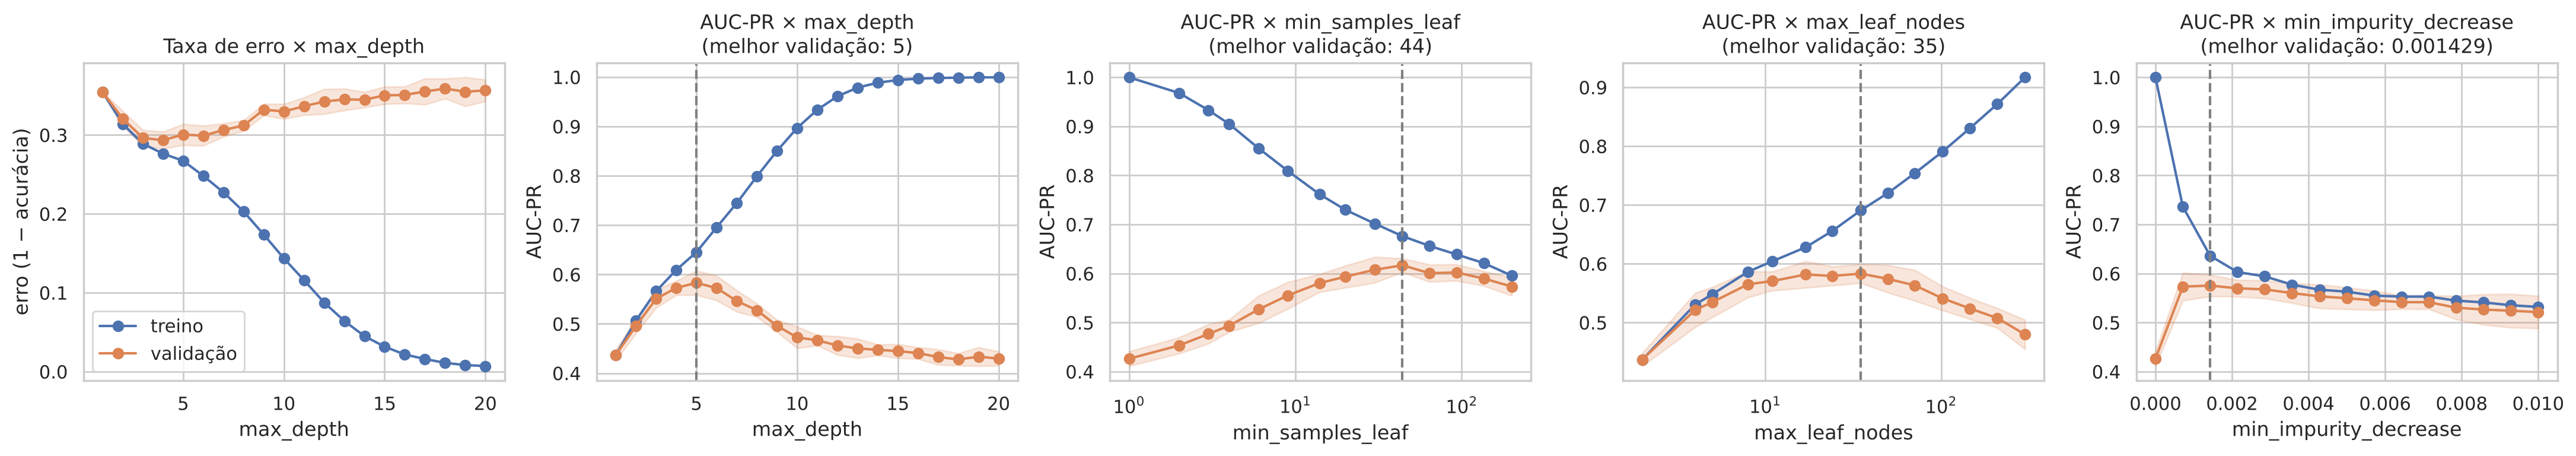

,hiperparâmetro,melhor valor,AUC-PR validação,AUC-PR treino,gap treino−validação
0,max_depth,5.000,0.583,0.645,0.062
1,min_samples_leaf,44.000,0.617,0.676,0.059
2,max_leaf_nodes,35.000,0.583,0.691,0.108
3,min_impurity_decrease,0.001,0.575,0.636,0.061


In [5]:
curvas = {
    "max_depth": np.arange(1, 21),
    "min_samples_leaf": np.unique(np.geomspace(1, 200, 15).astype(int)),
    "max_leaf_nodes": np.unique(np.geomspace(2, 300, 15).astype(int)),
    "min_impurity_decrease": np.linspace(0, 0.01, 15),
}
resultado_curvas = {}
for parametro, valores in curvas.items():
    for metrica, scorer in [("AUC_PR", "average_precision"), ("erro", "accuracy")]:
        tr, va = validation_curve(pipeline_arvore(), X_treino, y_treino,
                                  param_name=f"modelo__{parametro}", param_range=valores,
                                  cv=dobras, scoring=scorer, n_jobs=-1)
        if metrica == "erro":                    # erro = 1 - acurácia
            tr, va = 1 - tr, 1 - va
        resultado_curvas[(parametro, metrica)] = (valores, tr.mean(axis=1), va.mean(axis=1), va.std(axis=1))

fig, eixos = plt.subplots(1, 5, figsize=(22, 4))
valores, tr, va, dp = resultado_curvas[("max_depth", "erro")]
eixos[0].plot(valores, tr, "o-", label="treino"); eixos[0].plot(valores, va, "o-", label="validação")
eixos[0].fill_between(valores, va - dp, va + dp, alpha=0.2, color="C1")
eixos[0].set(title="Taxa de erro × max_depth", xlabel="max_depth", ylabel="erro (1 − acurácia)")
for eixo, parametro in zip(eixos[1:], curvas):
    valores, tr, va, dp = resultado_curvas[(parametro, "AUC_PR")]
    eixo.plot(valores, tr, "o-", label="treino"); eixo.plot(valores, va, "o-", label="validação")
    eixo.fill_between(valores, va - dp, va + dp, alpha=0.2, color="C1")
    melhor = valores[np.argmax(va)]
    eixo.axvline(melhor, ls="--", c="grey")
    eixo.set(title=f"AUC-PR × {parametro}\n(melhor validação: {melhor:.4g})", xlabel=parametro, ylabel="AUC-PR")
    if parametro in ("min_samples_leaf", "max_leaf_nodes"):
        eixo.set_xscale("log")
eixos[0].legend()
plt.tight_layout(); plt.show()

# Resumo numérico de cada curva: melhor valor e afastamento treino-validação nesse ponto.
resumo_curvas = []
for parametro in curvas:
    valores, tr, va, _ = resultado_curvas[(parametro, "AUC_PR")]
    i = int(np.argmax(va))
    resumo_curvas.append({"hiperparâmetro": parametro, "melhor valor": valores[i], "AUC-PR validação": va[i],
                          "AUC-PR treino": tr[i], "gap treino−validação": tr[i] - va[i]})
display(pd.DataFrame(resumo_curvas).round(3))

As cinco curvas contam a mesma história, de ângulos diferentes. Na taxa de erro, o treino cai continuamente até quase zero, enquanto a validação atinge o mínimo (cerca de 29%) entre as profundidades 4 e 5 e, a partir daí, volta a subir até retornar, na profundidade 20, ao nível do classificador trivial (35%). Esse formato de "U" na validação é a assinatura clássica do compromisso entre viés e variância: à esquerda, a árvore é simples demais (subajuste); à direita, decora o treino (sobreajuste).

Nas curvas de AUC-PR, por sua vez, todos os hiperparâmetros têm um ponto ótimo bem definido, mas com resultados diferentes. O `min_samples_leaf` é, isoladamente, o controle mais eficaz: com pelo menos **44 clientes por folha**, a AUC-PR de validação chega a **0,617**, enquanto o melhor `max_depth` (5) chega a 0,583 e o melhor `max_leaf_nodes` (35), também a 0,583, com o maior afastamento entre treino e validação (0,108). A explicação está no que cada um controla. A profundidade máxima corta **todos** os ramos na mesma altura, inclusive aqueles em que ainda haveria clientes suficientes para uma boa divisão. O tamanho mínimo da folha, em contrapartida, deixa a árvore crescer onde há dados e a interrompe apenas onde eles acabam; além disso, garante que a probabilidade de cada folha seja estimada com dezenas de clientes, o que torna o **ordenamento** dos clientes, justamente o que a AUC-PR mede, mais estável. Por fim, o `min_impurity_decrease` tem o pior pico (0,575) e uma faixa útil muito estreita: logo depois de 0,001, ele já poda divisões valiosas.

### 4.2 Busca em grade (`GridSearchCV`)

As curvas mostram o efeito de cada hiperparâmetro, mas não as interações entre eles: a melhor profundidade, por exemplo, depende de quantos clientes cada folha é obrigada a ter. Para capturar essas interações, fazemos uma ***busca em grade*** (`GridSearchCV`), que treina e valida, com as mesmas 5 dobras, todas as combinações de:

| Hiperparâmetro | Valores | Justificativa |
| --- | --- | --- |
| `criterion` | gini, entropy | as duas medidas de impureza da Seção 1.2 |
| `max_depth` | 3, 4, 5, 6, 8, 10, None | região do pico da curva de validação e controles (rasa e sem limite) |
| `min_samples_leaf` | 1, 10, 20, 40, 60, 80, 120 | de nenhuma restrição até ~4% do treino em cada folha, cobrindo com folga o pico da curva de validação |
| `min_samples_split` | 2, 100, 200 | padrão e duas restrições; valores menores que o dobro de `min_samples_leaf` não teriam efeito |
| `class_weight` | None, balanced | testa formalmente o ganho do balanceamento visto na Seção 3.2 |

São 588 combinações e, portanto, 2.940 treinos. Deixamos `max_leaf_nodes` e `min_impurity_decrease` fora da grade porque, como mostraram as curvas, eles controlam o mesmo aspecto que `max_depth` e `min_samples_leaf` (o tamanho final da árvore); incluí-los multiplicaria o custo por 25 sem acrescentar uma dimensão nova de controle. A escolha é feita pela AUC-PR média na validação (`refit="AUC_PR"`), e as demais métricas são registradas para análise.

In [6]:
grade_pre = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [3, 4, 5, 6, 8, 10, None],
    "modelo__min_samples_leaf": [1, 10, 20, 40, 60, 80, 120],
    "modelo__min_samples_split": [2, 100, 200],
    "modelo__class_weight": [None, "balanced"],
}
inicio = time.time()
busca_pre = GridSearchCV(pipeline_arvore(), grade_pre, cv=dobras, scoring=METRICAS, refit="AUC_PR",
                         return_train_score=True, n_jobs=-1).fit(X_treino, y_treino)
duracao_grade = time.time() - inicio

resultados_pre = pd.DataFrame(busca_pre.cv_results_)
resultados_pre.columns = [c.replace("param_modelo__", "") for c in resultados_pre.columns]
# None aparece como ausente nas tabelas; trocamos pelo texto "None" para facilitar a leitura.
for coluna in ["max_depth", "class_weight"]:
    resultados_pre[coluna] = resultados_pre[coluna].astype(object).where(resultados_pre[coluna].notna(), "None")
resultados_pre = resultados_pre.sort_values("rank_test_AUC_PR")
print(f"{len(resultados_pre)} combinações × {config.N_DOBRAS} dobras em {duracao_grade:.0f} s")
print(f"Melhor combinação: { {k.replace('modelo__', ''): v for k, v in busca_pre.best_params_.items()} }")

colunas_grade = ["criterion", "max_depth", "min_samples_leaf", "min_samples_split", "class_weight",
                 "mean_train_AUC_PR", "mean_test_AUC_PR", "std_test_AUC_PR", "mean_test_AUC_ROC",
                 "mean_test_recall", "mean_test_precisao"]
display(resultados_pre[colunas_grade].head(10).round(3))

arvore_pre = busca_pre.best_estimator_["modelo"]
print(f"Árvore da pré-poda: profundidade {arvore_pre.get_depth()}, {arvore_pre.get_n_leaves()} folhas")

588 combinações × 5 dobras em 40 s
Melhor combinação: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 40, 'min_samples_split': 100}


,criterion,max_depth,min_samples_leaf,min_samples_split,class_weight,mean_train_AUC_PR,mean_test_AUC_PR,std_test_AUC_PR,mean_test_AUC_ROC,mean_test_recall,mean_test_precisao
241,entropy,8,40,100,None,0.677,0.627,0.014,0.766,0.504,0.631
262,entropy,10,40,100,None,0.677,0.626,0.014,0.766,0.504,0.631
283,entropy,None,40,100,None,0.677,0.626,0.014,0.766,0.504,0.631
535,entropy,8,40,100,balanced,0.677,0.626,0.014,0.765,0.733,0.548
556,entropy,10,40,100,balanced,0.677,0.626,0.014,0.765,0.737,0.547
577,entropy,None,40,100,balanced,0.677,0.626,0.014,0.765,0.737,0.547
240,entropy,8,40,2,None,0.681,0.625,0.014,0.764,0.498,0.632
282,entropy,None,40,2,None,0.681,0.625,0.014,0.763,0.498,0.632
261,entropy,10,40,2,None,0.681,0.625,0.014,0.763,0.498,0.632
534,entropy,8,40,2,balanced,0.681,0.624,0.013,0.763,0.726,0.543


Árvore da pré-poda: profundidade 8, 51 folhas


A busca avaliou as 588 combinações em cerca de 100 segundos, e a vencedora usa **entropia, profundidade máxima 8, pelo menos 40 clientes por folha, pelo menos 100 clientes para dividir um nó e nenhum balanceamento**, com AUC-PR de validação de **0,627 ± 0,014** e AUC-ROC de 0,766. O afastamento entre treino (0,677) e validação é de 0,05, ou seja, cerca de um décimo do observado na árvore sem restrições.

As dez primeiras colocadas, no entanto, diferem apenas na terceira casa decimal, e o padrão entre elas é revelador. Todas têm `min_samples_leaf = 40`, mas `max_depth` varia entre 8, 10 e sem limite com resultados praticamente idênticos. Isso significa que, com folhas de 40 clientes, a árvore para de crescer sozinha por volta da profundidade 8, de modo que o limite de profundidade deixa de ser ativo. Na prática, portanto, o hiperparâmetro que de fato controla a complexidade desta árvore é o tamanho mínimo da folha, como as curvas da Seção 4.1 já sugeriam. A árvore resultante tem profundidade 8 e 51 folhas.

Outro padrão importante aparece na quarta linha: a mesma configuração com `class_weight="balanced"` tem AUC-PR praticamente igual (0,626), mas o recall no limiar 0,5 salta de 0,504 para 0,733, enquanto a precisão cai de 0,631 para 0,548. A seção seguinte aprofunda essa observação.

### 4.3 O que a grade revela além do vencedor

O primeiro colocado é apenas um ponto da grade; olhar o conjunto dos resultados, por outro lado, mostra quais decisões realmente importam. O mapa de calor abaixo mostra, para cada par `max_depth` × `min_samples_leaf`, a melhor AUC-PR de validação obtida com os demais hiperparâmetros livres, separado por `class_weight`. Em seguida, a tabela resume o melhor resultado de cada valor de `criterion` e de `class_weight`.

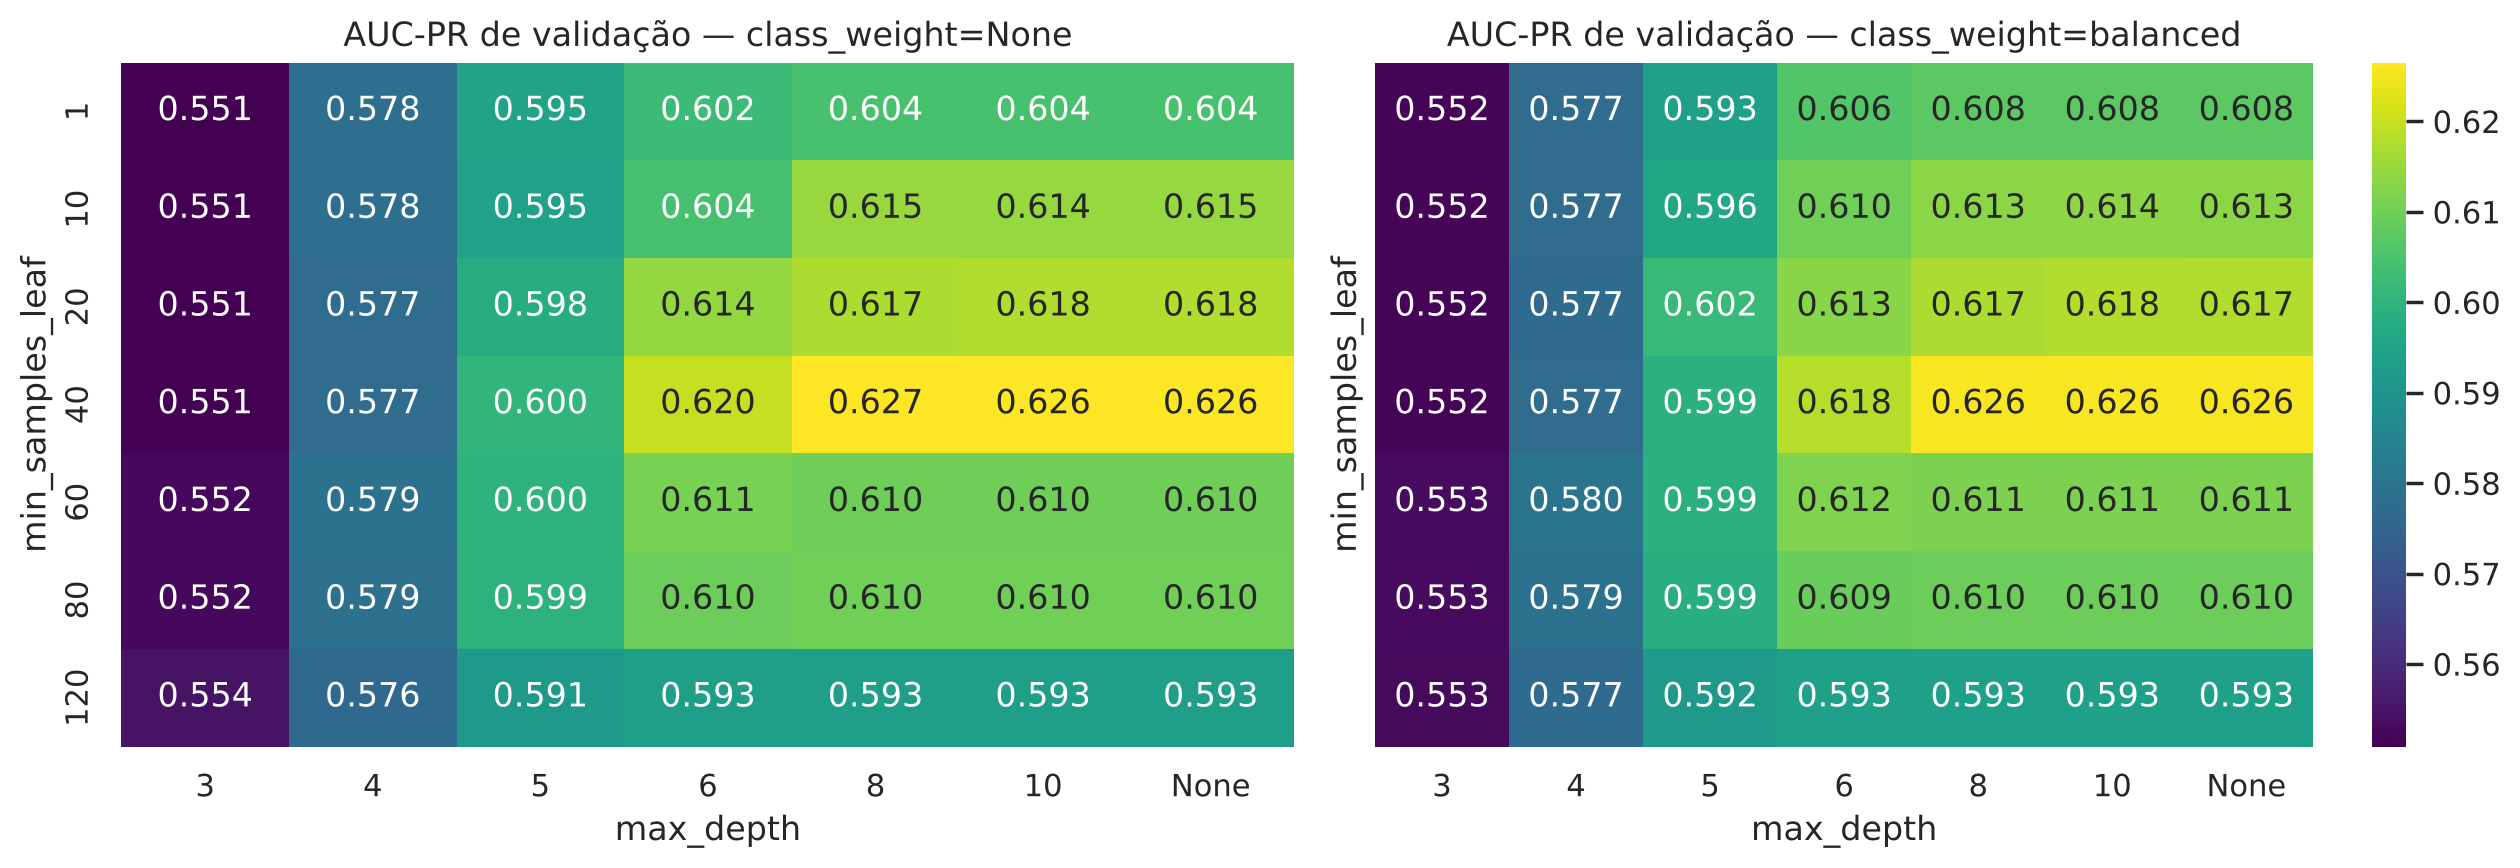

,hiperparâmetro,valor,melhor AUC-PR,AUC-ROC,"recall (limiar 0,5)","precisão (limiar 0,5)"
0,criterion,entropy,0.627,0.766,0.504,0.631
1,criterion,gini,0.623,0.763,0.727,0.547
2,class_weight,None,0.627,0.766,0.504,0.631
3,class_weight,balanced,0.626,0.765,0.733,0.548


In [7]:
resultados_pre["max_depth_txt"] = resultados_pre["max_depth"].astype(str)
ordem_prof = ["3", "4", "5", "6", "8", "10", "None"]
escala = resultados_pre["mean_test_AUC_PR"].quantile([0.05, 1.0]).to_numpy()   # mesma escala de cor nos dois mapas
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for eixo, peso in zip(eixos, ["None", "balanced"]):
    filtro = resultados_pre["class_weight"] == peso
    mapa = (resultados_pre[filtro].pivot_table(index="min_samples_leaf", columns="max_depth_txt",
                                               values="mean_test_AUC_PR", aggfunc="max")[ordem_prof])
    sns.heatmap(mapa, annot=True, fmt=".3f", cmap="viridis", vmin=escala[0], vmax=escala[1], ax=eixo, cbar=eixo is eixos[1])
    eixo.set(title=f"AUC-PR de validação — class_weight={peso}", xlabel="max_depth", ylabel="min_samples_leaf")
plt.tight_layout(); plt.show()

efeitos = []
for parametro in ["criterion", "class_weight"]:
    for valor, grupo in resultados_pre.groupby(resultados_pre[parametro].astype(str)):
        melhor = grupo.loc[grupo["mean_test_AUC_PR"].idxmax()]
        efeitos.append({"hiperparâmetro": parametro, "valor": valor, "melhor AUC-PR": melhor["mean_test_AUC_PR"],
                        "AUC-ROC": melhor["mean_test_AUC_ROC"], "recall (limiar 0,5)": melhor["mean_test_recall"],
                        "precisão (limiar 0,5)": melhor["mean_test_precisao"]})
display(pd.DataFrame(efeitos).round(3))

O mapa de calor torna visível o compromisso entre os dois hiperparâmetros. Em toda a coluna de profundidade 3, a AUC-PR fica em torno de 0,55, independentemente do tamanho da folha: a árvore é simples demais para que a folha faça diferença. À medida que a profundidade aumenta, o tamanho da folha passa a decidir: com folhas de 1 cliente, o desempenho estaciona em 0,60; com 40 clientes, chega ao máximo de 0,627; com 120, volta a cair para 0,59, porque as folhas ficam grandes demais para separar perfis diferentes. Além disso, a partir da profundidade 8 as colunas são idênticas, o que confirma que o limite de profundidade deixou de atuar.

Os dois painéis, por outro lado, são quase indistinguíveis, e a tabela confirma: o melhor resultado com `class_weight=None` (0,627) e com `balanced` (0,626) é o mesmo dentro do erro. Esse é um achado metodológico relevante. O balanceamento de classes **não melhora a capacidade da árvore de ordenar os clientes por risco**; ele apenas desloca as probabilidades para cima e, com isso, muda o ponto de operação no limiar 0,5. Ora, deslocar o ponto de operação é exatamente o que a escolha do limiar faz, e de forma mais controlada. Como a Seção 6 ajusta o limiar explicitamente, o `class_weight` torna-se redundante neste fluxo, e a escolha de `None` não traz prejuízo algum ao recall. Por fim, a entropia supera o Gini por apenas 0,004, diferença menor que o erro padrão da validação cruzada (cerca de 0,006); na prática, os dois critérios se equivalem nesta base.

## 5. Pós-poda por custo-complexidade (`ccp_alpha`)

### 5.1 O caminho de poda

A pós-poda segue a lógica oposta à da pré-poda: em vez de impedir o crescimento, ela cresce a árvore completa e depois a "apara". Para cada valor de $\alpha$, existe uma única subárvore que minimiza $R_\alpha(T) = R(T) + \alpha\,|T|$. Além disso, à medida que $\alpha$ aumenta, essas subárvores ótimas são encaixadas umas nas outras: cada aumento de $\alpha$ remove o "elo mais fraco", isto é, o ramo cujo ganho de pureza por folha é o menor. O scikit-learn calcula toda essa sequência com `cost_complexity_pruning_path`, que devolve os valores de $\alpha$ em que alguma poda acontece.

Para que a comparação com a pré-poda seja justa, usamos o mesmo `criterion` e o mesmo `class_weight` da melhor árvore da Seção 4, mas **sem nenhuma restrição de crescimento**. Assim, a única forma de controle passa a ser o `ccp_alpha`. O caminho é calculado sobre o treino já pré-processado apenas para ser visualizado; a escolha do $\alpha$, por sua vez, será feita na validação cruzada, com o `Pipeline` completo.

Configuração base da pós-poda: {'criterion': 'entropy', 'class_weight': None}
399 valores de alfa no caminho, de 2.17e-04 a 0.0520


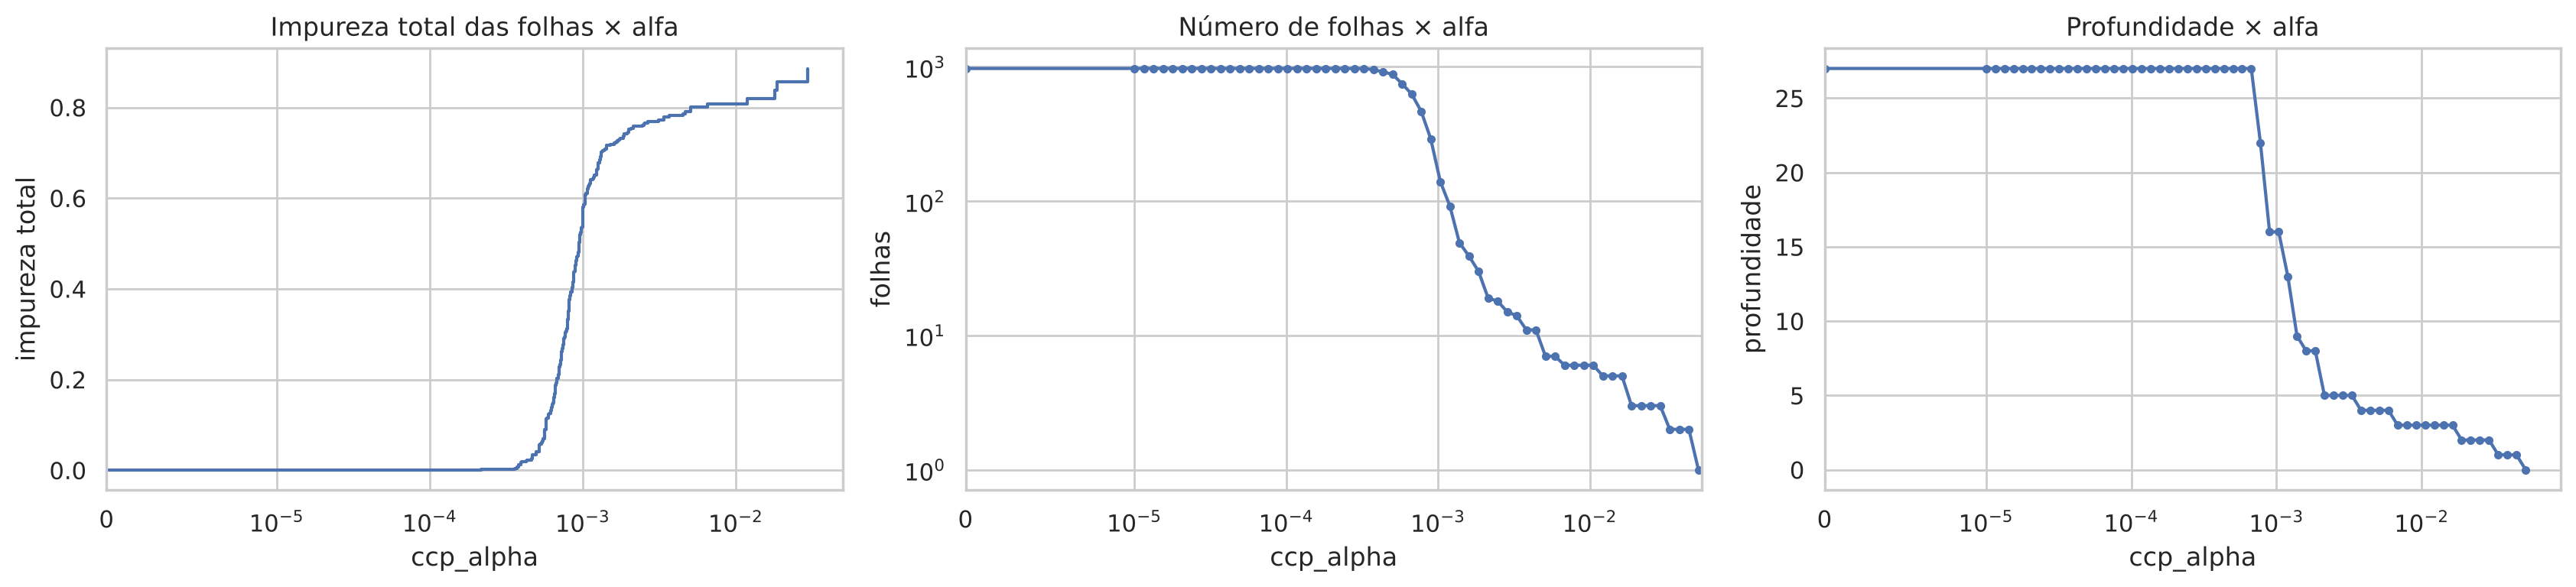

Árvore completa (alfa = 0): 973 folhas e profundidade 27


In [8]:
melhores_pre = {k.replace("modelo__", ""): v for k, v in busca_pre.best_params_.items()}
base_pos = {"criterion": melhores_pre["criterion"], "class_weight": melhores_pre["class_weight"]}

Z_treino = preprocessador.transform(X_treino)            # treino pré-processado (só para visualizar)
caminho = DecisionTreeClassifier(random_state=config.RANDOM_STATE, **base_pos).cost_complexity_pruning_path(Z_treino, y_treino)
print(f"Configuração base da pós-poda: {base_pos}")
print(f"{len(caminho.ccp_alphas)} valores de alfa no caminho, de {caminho.ccp_alphas[1]:.2e} a {caminho.ccp_alphas[-1]:.4f}")

# Para uma amostra de alfas ao longo do caminho, mede o tamanho da árvore resultante.
alfas_amostra = np.unique(np.concatenate([[0.0], np.geomspace(1e-5, caminho.ccp_alphas[-1], 60)]))
tamanhos = [DecisionTreeClassifier(random_state=config.RANDOM_STATE, ccp_alpha=a, **base_pos).fit(Z_treino, y_treino)
            for a in alfas_amostra]

fig, eixos = plt.subplots(1, 3, figsize=(17, 4))
eixos[0].step(caminho.ccp_alphas[:-1], caminho.impurities[:-1], where="post")
eixos[0].set(title="Impureza total das folhas × alfa", xlabel="ccp_alpha", ylabel="impureza total")
eixos[1].plot(alfas_amostra, [t.get_n_leaves() for t in tamanhos], "o-", ms=3)
eixos[1].set(title="Número de folhas × alfa", xlabel="ccp_alpha", ylabel="folhas", yscale="log")
eixos[2].plot(alfas_amostra, [t.get_depth() for t in tamanhos], "o-", ms=3)
eixos[2].set(title="Profundidade × alfa", xlabel="ccp_alpha", ylabel="profundidade")
for eixo in eixos:
    eixo.set_xscale("symlog", linthresh=1e-5); eixo.set_xlim(left=0)
plt.tight_layout(); plt.show()
print(f"Árvore completa (alfa = 0): {tamanhos[0].get_n_leaves()} folhas e profundidade {tamanhos[0].get_depth()}")

O caminho de poda mostra o tamanho do problema que a pós-poda precisa resolver: sem nenhuma restrição, a árvore cresce até 973 folhas e 27 níveis, isto é, em média uma folha para cada 3,6 clientes. Até um alfa de cerca de $5 \times 10^{-4}$, quase nada muda, porque as podas removem apenas divisões que isolavam um ou dois clientes e que, portanto, quase não reduziam a impureza. Entre $5 \times 10^{-4}$ e $2 \times 10^{-3}$, em seguida, a árvore desaba de quase mil folhas para algumas dezenas, e a impureza total das folhas sobe de praticamente zero para cerca de 0,7. Daí em diante, cada aumento de alfa remove ramos inteiros, até restar, no último alfa, apenas a raiz. A região interessante para a validação cruzada é, consequentemente, a faixa entre $10^{-3}$ e $10^{-2}$.

### 5.2 Escolha do alfa por validação cruzada

Agora testamos 40 valores de `ccp_alpha` espaçados em escala logarítmica entre $10^{-4}$ e o último alfa do caminho (que reduziria a árvore a um único nó), sempre com o `Pipeline` completo e as mesmas 5 dobras. Além do alfa de maior AUC-PR, calculamos o alfa sugerido pela ***regra de um erro padrão*** (Breiman et al., 1984, o mesmo trabalho que propôs o CART): entre todos os alfas cuja AUC-PR fica a menos de um erro padrão da melhor, escolhe-se o **maior**, ou seja, o da árvore mais simples. A ideia é que diferenças menores que o erro padrão não são distinguíveis do ruído da validação cruzada e, portanto, não justificam uma árvore mais complexa.

Alfa de maior AUC-PR: 0.00290 (AUC-PR = 0.592)
Erro padrão do melhor: 0.0089 -> limite de AUC-PR = 0.583
Alfa pela regra de 1 erro padrão: 0.00290


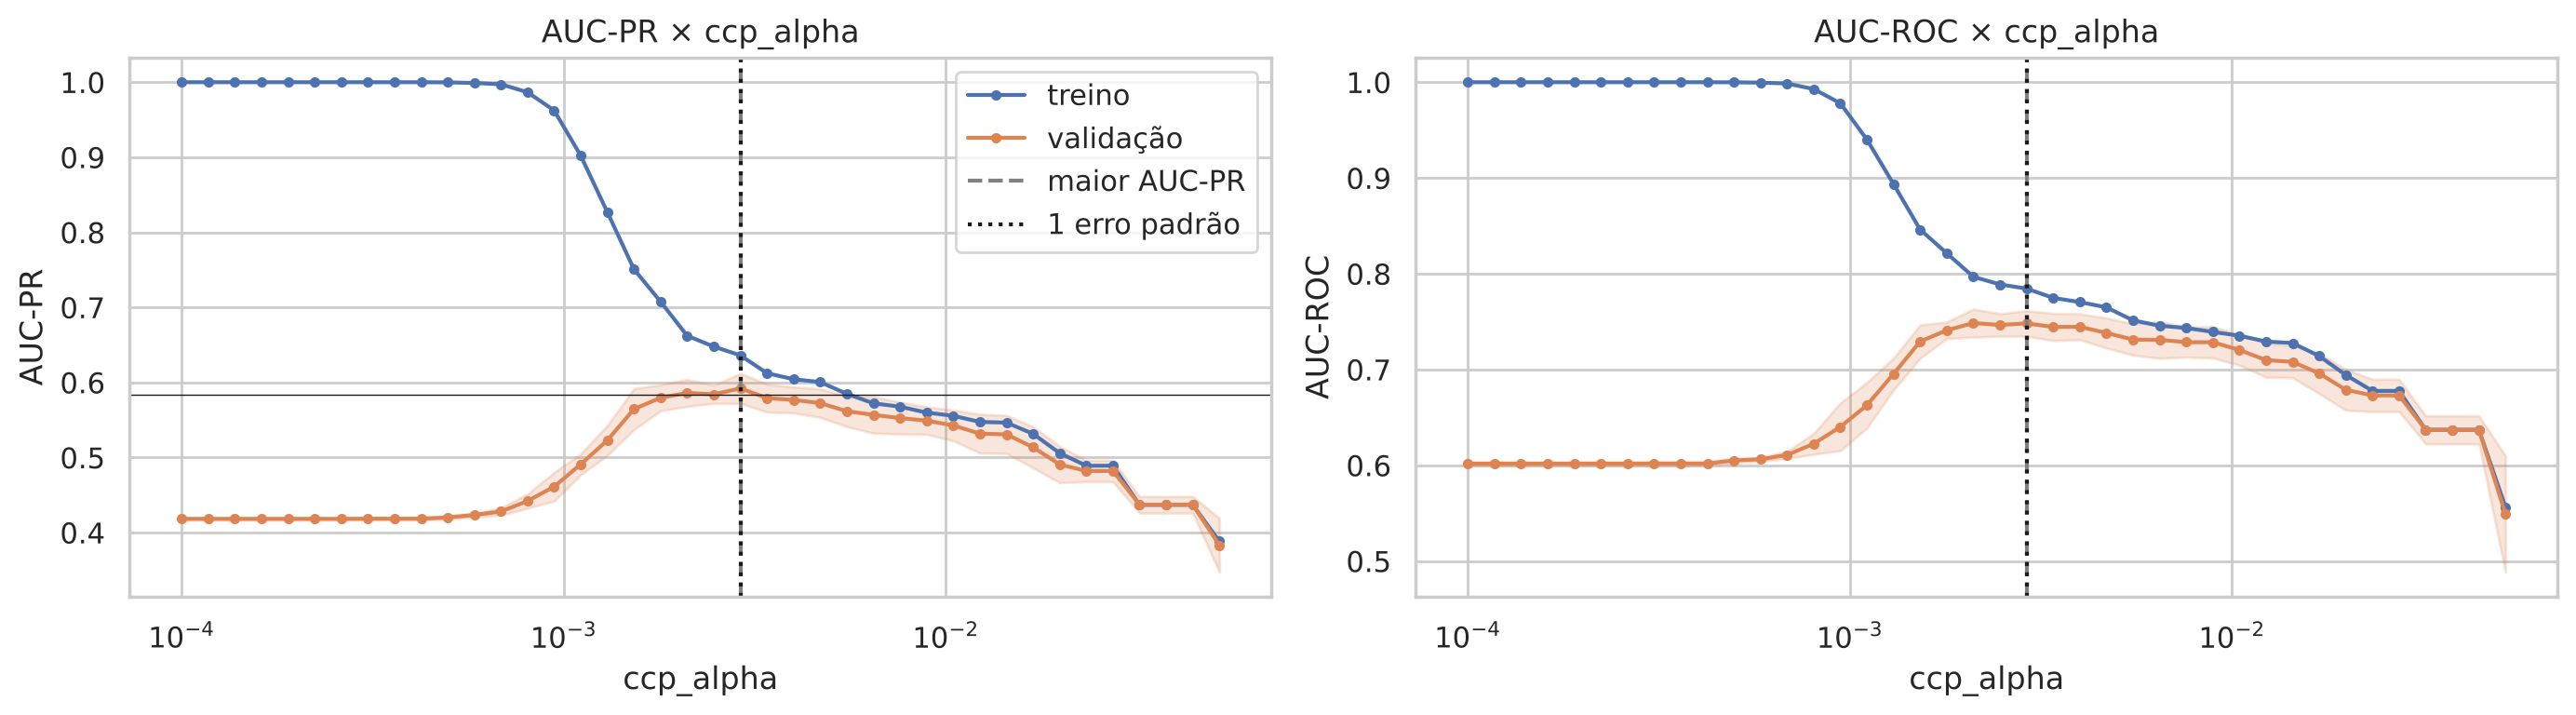

In [9]:
grade_alfas = np.geomspace(1e-4, caminho.ccp_alphas[-1], 40)
busca_pos = GridSearchCV(pipeline_arvore(**base_pos), {"modelo__ccp_alpha": grade_alfas}, cv=dobras,
                         scoring=METRICAS, refit="AUC_PR", return_train_score=True, n_jobs=-1).fit(X_treino, y_treino)
resultados_pos = pd.DataFrame(busca_pos.cv_results_)
resultados_pos["alfa"] = resultados_pos["param_modelo__ccp_alpha"].astype(float)

# Regra de um erro padrão: maior alfa cuja AUC-PR média >= melhor AUC-PR - erro padrão do melhor.
i_melhor = resultados_pos["mean_test_AUC_PR"].idxmax()
erro_padrao = resultados_pos.loc[i_melhor, "std_test_AUC_PR"] / np.sqrt(config.N_DOBRAS)
limite = resultados_pos.loc[i_melhor, "mean_test_AUC_PR"] - erro_padrao
alfa_melhor = resultados_pos.loc[i_melhor, "alfa"]
alfa_1ep = resultados_pos.loc[resultados_pos["mean_test_AUC_PR"] >= limite, "alfa"].max()
print(f"Alfa de maior AUC-PR: {alfa_melhor:.5f} (AUC-PR = {resultados_pos.loc[i_melhor, 'mean_test_AUC_PR']:.3f})")
print(f"Erro padrão do melhor: {erro_padrao:.4f} -> limite de AUC-PR = {limite:.3f}")
print(f"Alfa pela regra de 1 erro padrão: {alfa_1ep:.5f}")

fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
for eixo, (metrica, rotulo) in zip(eixos, [("AUC_PR", "AUC-PR"), ("AUC_ROC", "AUC-ROC")]):
    eixo.plot(resultados_pos["alfa"], resultados_pos[f"mean_train_{metrica}"], "o-", ms=3, label="treino")
    eixo.plot(resultados_pos["alfa"], resultados_pos[f"mean_test_{metrica}"], "o-", ms=3, label="validação")
    eixo.fill_between(resultados_pos["alfa"], resultados_pos[f"mean_test_{metrica}"] - resultados_pos[f"std_test_{metrica}"],
                      resultados_pos[f"mean_test_{metrica}"] + resultados_pos[f"std_test_{metrica}"], alpha=0.2, color="C1")
    eixo.axvline(alfa_melhor, ls="--", c="grey", label="maior AUC-PR")
    eixo.axvline(alfa_1ep, ls=":", c="k", label="1 erro padrão")
    eixo.set(xscale="log", xlabel="ccp_alpha", ylabel=rotulo, title=f"{rotulo} × ccp_alpha")
eixos[0].axhline(limite, c="k", lw=0.5)
eixos[0].legend(); plt.tight_layout(); plt.show()

A curva de validação da pós-poda tem o mesmo formato das curvas da pré-poda, só que espelhado, já que aqui a complexidade **diminui** da esquerda para a direita. Com alfa pequeno, a árvore é quase a completa: AUC-PR de 1,0 no treino e de 0,42 na validação. Conforme o alfa cresce, o treino cai continuamente, ao passo que a validação sobe até o máximo de **0,592**, em alfa = 0,0029, e depois volta a cair, quando a poda começa a remover estrutura útil e as duas curvas convergem para baixo (subajuste).

Neste caso, a regra de um erro padrão indica o **mesmo** alfa do máximo. Isso acontece porque a curva cai rapidamente logo depois do pico: o próximo alfa da grade já fica abaixo do limite de 0,583. Assim, não existe uma árvore mais simples que seja estatisticamente equivalente, e a árvore pós-podada fica com 15 folhas e profundidade 5.

### 5.3 Pré-poda × pós-poda

Com as duas estratégias otimizadas, chega o momento da comparação exigida pelo miniprojeto. Além delas, testamos uma hipótese própria: a de que as duas estratégias são **complementares**, e não rivais. A pré-poda garante folhas com muitos clientes e, portanto, probabilidades mais bem estimadas, ao passo que a pós-poda remove os ramos que, mesmo com folhas grandes, não compensam o seu tamanho. Por isso, incluímos uma ***árvore híbrida***, que parte dos hiperparâmetros vencedores da pré-poda e recebe, em seguida, uma busca de `ccp_alpha` nas mesmas condições da Seção 5.2.

A tabela reúne, para cada candidata, as métricas médias de validação, a AUC-PR de treino (para medir o afastamento) e o tamanho da árvore final. Para a pós-poda pura, mostramos o alfa de maior AUC-PR e, quando for diferente, também o da regra de um erro padrão.

A escolha da árvore que segue para o teste é feita por uma regra definida **antes** de olhar o teste: fica a de maior AUC-PR de validação; porém, se a diferença para outra candidata for menor que um erro padrão, preferimos a que tiver menos folhas, por ser mais simples de interpretar e menos propensa a sobreajuste.

In [10]:
# Árvore híbrida: hiperparâmetros da pré-poda + busca de ccp_alpha.
busca_hibrida = GridSearchCV(pipeline_arvore(**melhores_pre), {"modelo__ccp_alpha": np.concatenate([[0.0], grade_alfas])},
                             cv=dobras, scoring="average_precision", n_jobs=-1).fit(X_treino, y_treino)
alfa_hibrida = busca_hibrida.best_params_["modelo__ccp_alpha"]
print(f"Árvore híbrida: melhor ccp_alpha sobre a pré-poda = {alfa_hibrida:.5f}")

candidatas = {
    "pré-poda (GridSearch)": busca_pre.best_estimator_["modelo"].get_params(),
    "pós-poda (maior AUC-PR)": pipeline_arvore(**base_pos, ccp_alpha=alfa_melhor)["modelo"].get_params(),
}
if alfa_1ep != alfa_melhor:
    candidatas["pós-poda (1 erro padrão)"] = pipeline_arvore(**base_pos, ccp_alpha=alfa_1ep)["modelo"].get_params()
if alfa_hibrida > 0:
    candidatas["híbrida (pré + pós)"] = pipeline_arvore(**melhores_pre, ccp_alpha=alfa_hibrida)["modelo"].get_params()
else:
    print("A poda adicional não melhorou a pré-poda: a híbrida coincide com ela e não entra na comparação.")
linhas = []
for nome, params in candidatas.items():
    params = {k: v for k, v in params.items() if k != "random_state"}
    linha = avaliar_cv(pipeline_arvore(**params), nome)
    arvore = DecisionTreeClassifier(random_state=config.RANDOM_STATE, **params).fit(Z_treino, y_treino)
    linha.update({"profundidade": arvore.get_depth(), "folhas": arvore.get_n_leaves(), "params": params})
    linhas.append(linha)
comparacao = pd.DataFrame(linhas).set_index("modelo")
display(comparacao[["AUC_PR (treino)", "AUC_PR (validação)", "AUC_PR desvio (validação)", "AUC_ROC (validação)",
                    "recall (validação)", "precisao (validação)", "profundidade", "folhas"]].round(3))

# Regra de escolha (definida antes de olhar o teste).
ordenadas = comparacao.sort_values("AUC_PR (validação)", ascending=False)
ep = ordenadas["AUC_PR desvio (validação)"].iloc[0] / np.sqrt(config.N_DOBRAS)
empatadas = ordenadas[ordenadas["AUC_PR (validação)"] >= ordenadas["AUC_PR (validação)"].iloc[0] - ep]
nome_escolhida = empatadas.sort_values(["folhas", "AUC_PR (validação)"], ascending=[True, False]).index[0]
params_escolhida = comparacao.loc[nome_escolhida, "params"]
print(f"Erro padrão da melhor AUC-PR: {ep:.4f}. Candidatas empatadas: {list(empatadas.index)}")
print(f"Árvore escolhida: {nome_escolhida}")
print(f"Hiperparâmetros não padrão: { {k: (v.item() if hasattr(v, 'item') else v) for k, v in params_escolhida.items() if v != DecisionTreeClassifier().get_params()[k]} }")

Árvore híbrida: melhor ccp_alpha sobre a pré-poda = 0.00036


,AUC_PR (treino),AUC_PR (validação),AUC_PR desvio (validação),AUC_ROC (validação),recall (validação),precisao (validação),profundidade,folhas
modelo,,,,,,,,
pré-poda (GridSearch),0.677,0.627,0.014,0.766,0.504,0.631,8,51
pós-poda (maior AUC-PR),0.636,0.592,0.020,0.748,0.441,0.623,5,15
híbrida (pré + pós),0.676,0.627,0.014,0.766,0.504,0.631,8,48


Erro padrão da melhor AUC-PR: 0.0060. Candidatas empatadas: ['híbrida (pré + pós)', 'pré-poda (GridSearch)']
Árvore escolhida: híbrida (pré + pós)
Hiperparâmetros não padrão: {'ccp_alpha': 0.0003606324172236214, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 40, 'min_samples_split': 100}


A comparação responde ao teste obrigatório do miniprojeto de forma clara: **nesta base, a pré-poda supera a pós-poda**. A árvore da grade alcança AUC-PR de 0,627 contra 0,592 da pós-poda pura, uma diferença de 0,035, que corresponde a quase seis erros padrão (0,006) e, portanto, não pode ser atribuída ao acaso. A AUC-ROC segue a mesma ordem (0,766 contra 0,748).

À primeira vista, esse resultado contraria a intuição de que a pós-poda seria superior por "enxergar" a árvore inteira antes de cortar. A explicação, porém, está no **critério** de cada estratégia. O custo-complexidade avalia os ramos pela impureza no **treino** e penaliza apenas o **número** de folhas; ele não impede que uma folha tenha 2 ou 3 clientes. Para eliminar o sobreajuste, o alfa ótimo precisou, então, reduzir a árvore a apenas 15 folhas, descartando junto divisões úteis. A pré-poda por tamanho de folha, por sua vez, ataca diretamente a causa do sobreajuste nesta base (folhas pequenas, com probabilidades mal estimadas) e, por isso, consegue manter uma árvore mais rica, com 51 folhas, sem decorar o treino.

A hipótese da árvore híbrida, por fim, confirmou-se apenas em parte. A poda adicional (alfa = 0,00036) removeu 3 folhas da árvore da pré-poda sem nenhuma perda de AUC-PR (0,627 nas duas). Como a diferença entre as duas é muito menor que um erro padrão, a regra de escolha favoreceu a **árvore híbrida**, que é a mais simples entre as empatadas. A pós-poda, portanto, não substituiu a pré-poda, mas funcionou bem como um ajuste fino sobre ela.

## 6. O limiar de decisão e o trade-off recall × precisão

Uma árvore não devolve apenas "cancela" ou "não cancela": em cada folha, ela calcula uma **probabilidade** de churn, e a classe só é decidida comparando essa probabilidade com um limiar, por padrão 0,5. Esse limiar, contudo, não é uma propriedade do modelo, e sim uma ***decisão de negócio***: baixá-lo aumenta o recall (mais clientes são acionados) e, em troca, reduz a precisão (mais ofertas vão para quem ficaria).

Para escolher o limiar sem tocar no teste, usamos as ***previsões fora da dobra*** (*out-of-fold*): com `cross_val_predict`, cada cliente do treino recebe a probabilidade dada por um modelo que **não** o viu durante o treinamento. Com essas probabilidades "honestas", traçamos a precisão, o recall e a fração de clientes acionados em todos os limiares possíveis. Em seguida, aplicamos a regra da Seção 1.4: o limiar escolhido é o **maior** limiar que ainda garante recall de pelo menos 80%, pois é ele que atinge a meta acionando o menor número de clientes.

Há, entretanto, uma particularidade das árvores: como todos os clientes de uma mesma folha recebem a mesma probabilidade, só existem tantos limiares distintos quantas folhas. Por isso, o recall não pode ser ajustado continuamente; ele "salta" de uma folha para a outra, e o limiar escolhido é o primeiro degrau que cruza a meta.

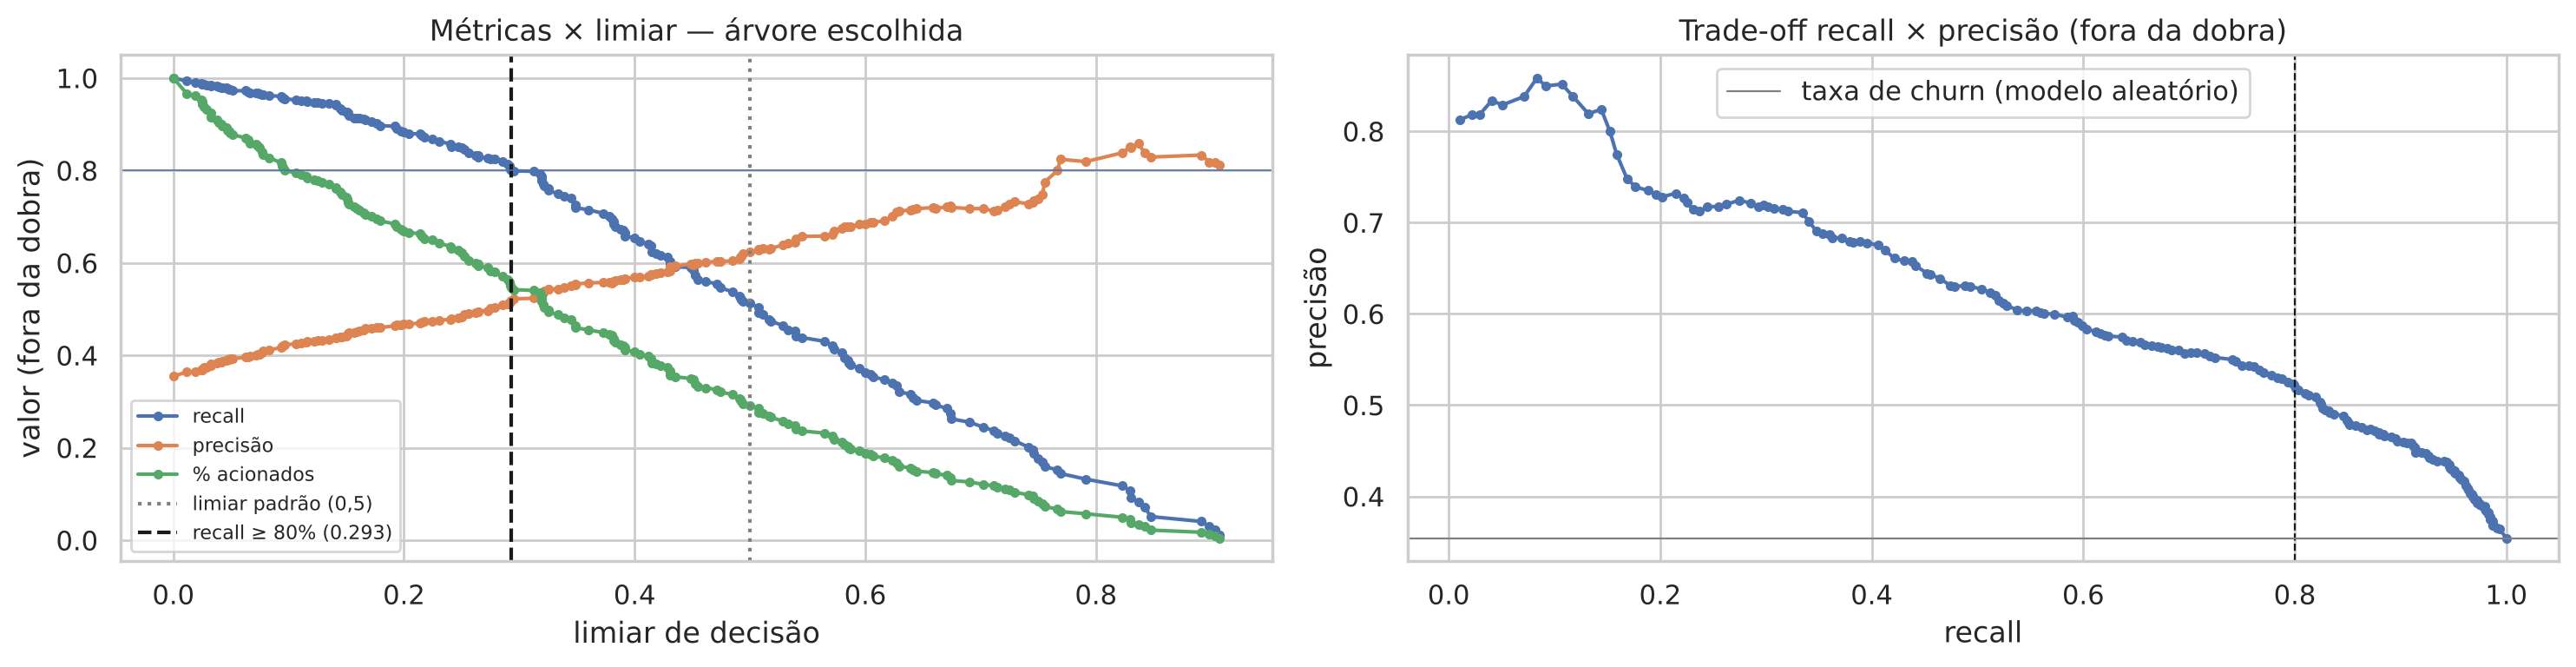

,recall-alvo,limiar,recall obtido,precisão,% acionados,acionados por churn detectado
0,0.60,0.430,0.603,0.583,0.366,1.715
1,0.70,0.378,0.702,0.557,0.446,1.794
2,0.80,0.293,0.801,0.519,0.547,1.927
3,0.90,0.176,0.903,0.460,0.696,2.175
4,0.95,0.115,0.951,0.428,0.788,2.337


In [11]:
def limiar_para_recall(prob, y, alvo=config.RECALL_ALVO):
    # Maior limiar cujo recall (nas previsões fora da dobra) ainda atinge o alvo.
    candidatos = np.sort(np.unique(prob))[::-1]
    for t in candidatos:
        if recall_score(y, prob >= t) >= alvo:
            return float(t)
    return float(candidatos[-1])

def curva_de_limiares(prob, y):
    return pd.DataFrame([{"limiar": t, "recall": recall_score(y, prob >= t),
                          "precisão": precision_score(y, prob >= t, zero_division=0),
                          "F2": fbeta_score(y, prob >= t, beta=config.BETA),
                          "% acionados": (prob >= t).mean()} for t in np.unique(prob)])

modelo_escolhido = pipeline_arvore(**params_escolhida)
prob_oof = cross_val_predict(modelo_escolhido, X_treino, y_treino, cv=dobras, method="predict_proba")[:, 1]
curva_limiar = curva_de_limiares(prob_oof, y_treino)
limiar_escolhido = limiar_para_recall(prob_oof, y_treino)

fig, eixos = plt.subplots(1, 2, figsize=(15, 4))
for coluna in ["recall", "precisão", "% acionados"]:
    eixos[0].plot(curva_limiar["limiar"], curva_limiar[coluna], "o-", ms=3, label=coluna)
eixos[0].axvline(0.5, c="grey", ls=":", label="limiar padrão (0,5)")
eixos[0].axvline(limiar_escolhido, c="k", ls="--", label=f"recall ≥ {config.RECALL_ALVO:.0%} ({limiar_escolhido:.3f})")
eixos[0].axhline(config.RECALL_ALVO, c="C0", lw=0.6)
eixos[0].set(xlabel="limiar de decisão", ylabel="valor (fora da dobra)", title="Métricas × limiar — árvore escolhida")
eixos[0].legend(fontsize=8)
eixos[1].plot(curva_limiar["recall"], curva_limiar["precisão"], "o-", ms=3)
eixos[1].axvline(config.RECALL_ALVO, c="k", ls="--", lw=0.8)
eixos[1].axhline(y_treino.mean(), c="grey", lw=0.8, label="taxa de churn (modelo aleatório)")
eixos[1].set(xlabel="recall", ylabel="precisão", title="Trade-off recall × precisão (fora da dobra)")
eixos[1].legend(); plt.tight_layout(); plt.show()

# Trade-off para algumas metas de recall: quantos clientes é preciso acionar em cada uma.
tradeoff = []
for alvo in [0.60, 0.70, 0.80, 0.90, 0.95]:
    t = limiar_para_recall(prob_oof, y_treino, alvo)
    linha = curva_limiar[curva_limiar["limiar"] == t].iloc[0]
    tradeoff.append({"recall-alvo": alvo, "limiar": t, "recall obtido": linha["recall"], "precisão": linha["precisão"],
                     "% acionados": linha["% acionados"], "acionados por churn detectado": 1 / linha["precisão"]})
display(pd.DataFrame(tradeoff).round(3))

O gráfico da esquerda mostra o compromisso entre as três quantidades. No limiar padrão de 0,5, a árvore escolhida antecipa apenas cerca de metade dos cancelamentos, o que é insuficiente para o objetivo de retenção. Para atingir a meta de 80%, o limiar precisa descer para **0,293**; nesse ponto, a precisão fora da dobra é de **0,519** e a empresa acionaria **54,7%** dos clientes. Em termos operacionais, isso equivale a acionar 1,93 cliente para cada cancelamento detectado, ao passo que, escolhendo clientes ao acaso, seriam necessários 2,82.

A tabela de metas, por sua vez, quantifica o ***trade-off entre recall e precisão*** que deverá ser defendido na apresentação. Cada ponto adicional de recall custa cada vez mais caro: passar de 60% para 70% de recall exige acionar 8 pontos percentuais a mais da base, mas passar de 80% para 90% exige 15 pontos a mais, e chegar a 95% obriga a acionar quase 80% dos clientes, já muito perto da solução trivial. A meta de 80% fica, portanto, na região em que o modelo ainda agrega valor claro sobre a escolha aleatória. Se o custo de uma oferta de retenção for muito menor que a receita perdida, a empresa pode, ainda assim, preferir 90%; essa decisão, contudo, depende de números de negócio que não estão na base e deve ser tratada como um parâmetro, e não como um resultado do modelo.

## 7. Avaliação final no teste e análise de sobreajuste

### 7.1 Métricas no treino e no teste

Chegou, enfim, o momento de usar o teste. A árvore escolhida é treinada com o treino inteiro (o pré-processamento, consequentemente, também é reajustado nele, reproduzindo a Versão A) e avaliada **uma única vez** nos 1.493 clientes de teste, com o limiar definido na Seção 6. Para documentar o processo, mostramos também as outras duas candidatas, cada uma com o seu próprio limiar de recall 80% obtido da mesma forma; no entanto, a escolha já foi feita na Seção 5.3 e não muda com o que aparecer aqui.

O miniprojeto pede o ***gap*** entre treino e teste. Ele é a diferença entre o desempenho nos clientes que o modelo viu e nos que ele nunca viu; quanto maior o gap, mais o modelo decorou o treino.

In [12]:
def metricas(y, prob, limiar):
    previsto = (prob >= limiar).astype(int)
    return {"recall": recall_score(y, previsto), "precisão": precision_score(y, previsto, zero_division=0),
            "F2": fbeta_score(y, previsto, beta=config.BETA), "acurácia": accuracy_score(y, previsto),
            "% acionados": previsto.mean(), "AUC-ROC": roc_auc_score(y, prob),
            "AUC-PR": average_precision_score(y, prob)}

modelos_finais, limiares_finais, linhas = {}, {}, []
for nome in comparacao.index:
    pipeline = pipeline_arvore(**comparacao.loc[nome, "params"])
    if nome == nome_escolhida:
        limiar = limiar_escolhido
    else:                                       # mesmo procedimento da Seção 6, para cada candidata
        oof = cross_val_predict(pipeline, X_treino, y_treino, cv=dobras, method="predict_proba")[:, 1]
        limiar = limiar_para_recall(oof, y_treino)
    modelo = pipeline.fit(X_treino, y_treino)
    modelos_finais[nome], limiares_finais[nome] = modelo, limiar
    for conjunto, X, y in [("treino", X_treino, y_treino), ("teste", X_teste, y_teste)]:
        linhas.append({"modelo": nome + (" ★" if nome == nome_escolhida else ""), "limiar": round(limiar, 3),
                       "conjunto": conjunto, **metricas(y, modelo.predict_proba(X)[:, 1], limiar)})
avaliacao = pd.DataFrame(linhas).set_index(["modelo", "limiar", "conjunto"])
display(avaliacao.round(3))

# Gap treino − teste da árvore escolhida.
arvore_final = modelos_finais[nome_escolhida]
prob_treino = arvore_final.predict_proba(X_treino)[:, 1]
prob_teste = arvore_final.predict_proba(X_teste)[:, 1]
m_tr, m_te = metricas(y_treino, prob_treino, limiar_escolhido), metricas(y_teste, prob_teste, limiar_escolhido)
gap = pd.DataFrame({"treino": m_tr, "teste": m_te}).T
gap.loc["gap (treino − teste)"] = gap.loc["treino"] - gap.loc["teste"]
print(f"Árvore escolhida ({nome_escolhida}), limiar {limiar_escolhido:.3f}:")
display(gap.round(3))

recall  precisão     F2  acurácia  \
modelo                  limiar conjunto                                      
pré-poda (GridSearch)   0.292  treino     0.794     0.561  0.733     0.707   
                               teste      0.737     0.536  0.686     0.681   
pós-poda (maior AUC-PR) 0.302  treino     0.882     0.495  0.763     0.639   
                               teste      0.862     0.481  0.744     0.622   
híbrida (pré + pós) ★   0.293  treino     0.804     0.553  0.737     0.701   
                               teste      0.760     0.531  0.700     0.677   

                                         % acionados  AUC-ROC  AUC-PR  
modelo                  limiar conjunto                                
pré-poda (GridSearch)   0.292  treino          0.502    0.804   0.676  
                               teste           0.488    0.758   0.616  
pós-poda (maior AUC-PR) 0.302  treino          0.632    0.769   0.609  
                               teste           0.635    0.742   0.578  
híbrida (pré + pós) ★   0.293  treino          0.515    0.804   0.675  
                               teste           0.507    0.756   0.615

Árvore escolhida (híbrida (pré + pós)), limiar 0.293:


,recall,precisão,F2,acurácia,% acionados,AUC-ROC,AUC-PR
treino,0.804,0.553,0.737,0.701,0.515,0.804,0.675
teste,0.760,0.531,0.700,0.677,0.507,0.756,0.615
gap (treino − teste),0.044,0.022,0.037,0.023,0.008,0.047,0.060


No teste, a árvore escolhida antecipa **76,0%** dos cancelamentos, com precisão de **53,1%**, acionando 50,7% dos clientes; a AUC-ROC é de **0,756** e a AUC-PR, de **0,615**. Dois pontos merecem destaque.

Primeiro, o recall de teste ficou abaixo da meta de 80% definida nas previsões fora da dobra (80,1%). Essa diferença era esperada, já que o limiar foi calibrado em uma amostra e aplicado a outra, e é agravada pela natureza "em degraus" das probabilidades da árvore. Por isso mesmo, em produção, a meta deve ser monitorada e o limiar recalibrado periodicamente. Ainda assim, a estimativa da validação cruzada se mostrou confiável: a AUC-PR de validação (0,627) e a de teste (0,615) diferem em 0,012, dentro de um desvio padrão das dobras (0,014).

Segundo, o ***gap*** entre treino e teste é moderado: 0,060 na AUC-PR, 0,047 na AUC-ROC e 4,4 pontos percentuais no recall. Para comparação, a árvore sem restrições tinha um afastamento de 0,57 na AUC-PR entre treino e validação. O controle de complexidade, portanto, reduziu o sobreajuste em cerca de dez vezes, ainda que não o tenha eliminado por completo. Por fim, a ordem das candidatas no teste é a mesma da validação cruzada (pré-poda e híbrida à frente da pós-poda pura), o que reforça que a escolha não dependeu de sorte. A pós-poda pura tem recall de teste maior (86,2%) apenas porque, com 15 folhas, o seu degrau de probabilidade mais próximo da meta acionou 63,5% dos clientes; a sua precisão, em contrapartida, é a menor das três.

### 7.2 Matriz de confusão, curva ROC e curva precisão-recall

A matriz de confusão traduz as métricas em clientes: quantos cancelamentos o modelo antecipou, quantos deixou escapar e quantas ofertas iriam para clientes que não sairiam. As curvas ROC e precisão-recall, por sua vez, mostram o desempenho em **todos** os limiares ao mesmo tempo; o ponto marcado em cada uma é o limiar escolhido na Seção 6. As curvas do treino aparecem tracejadas para evidenciar, mais uma vez, o afastamento entre os dois conjuntos.

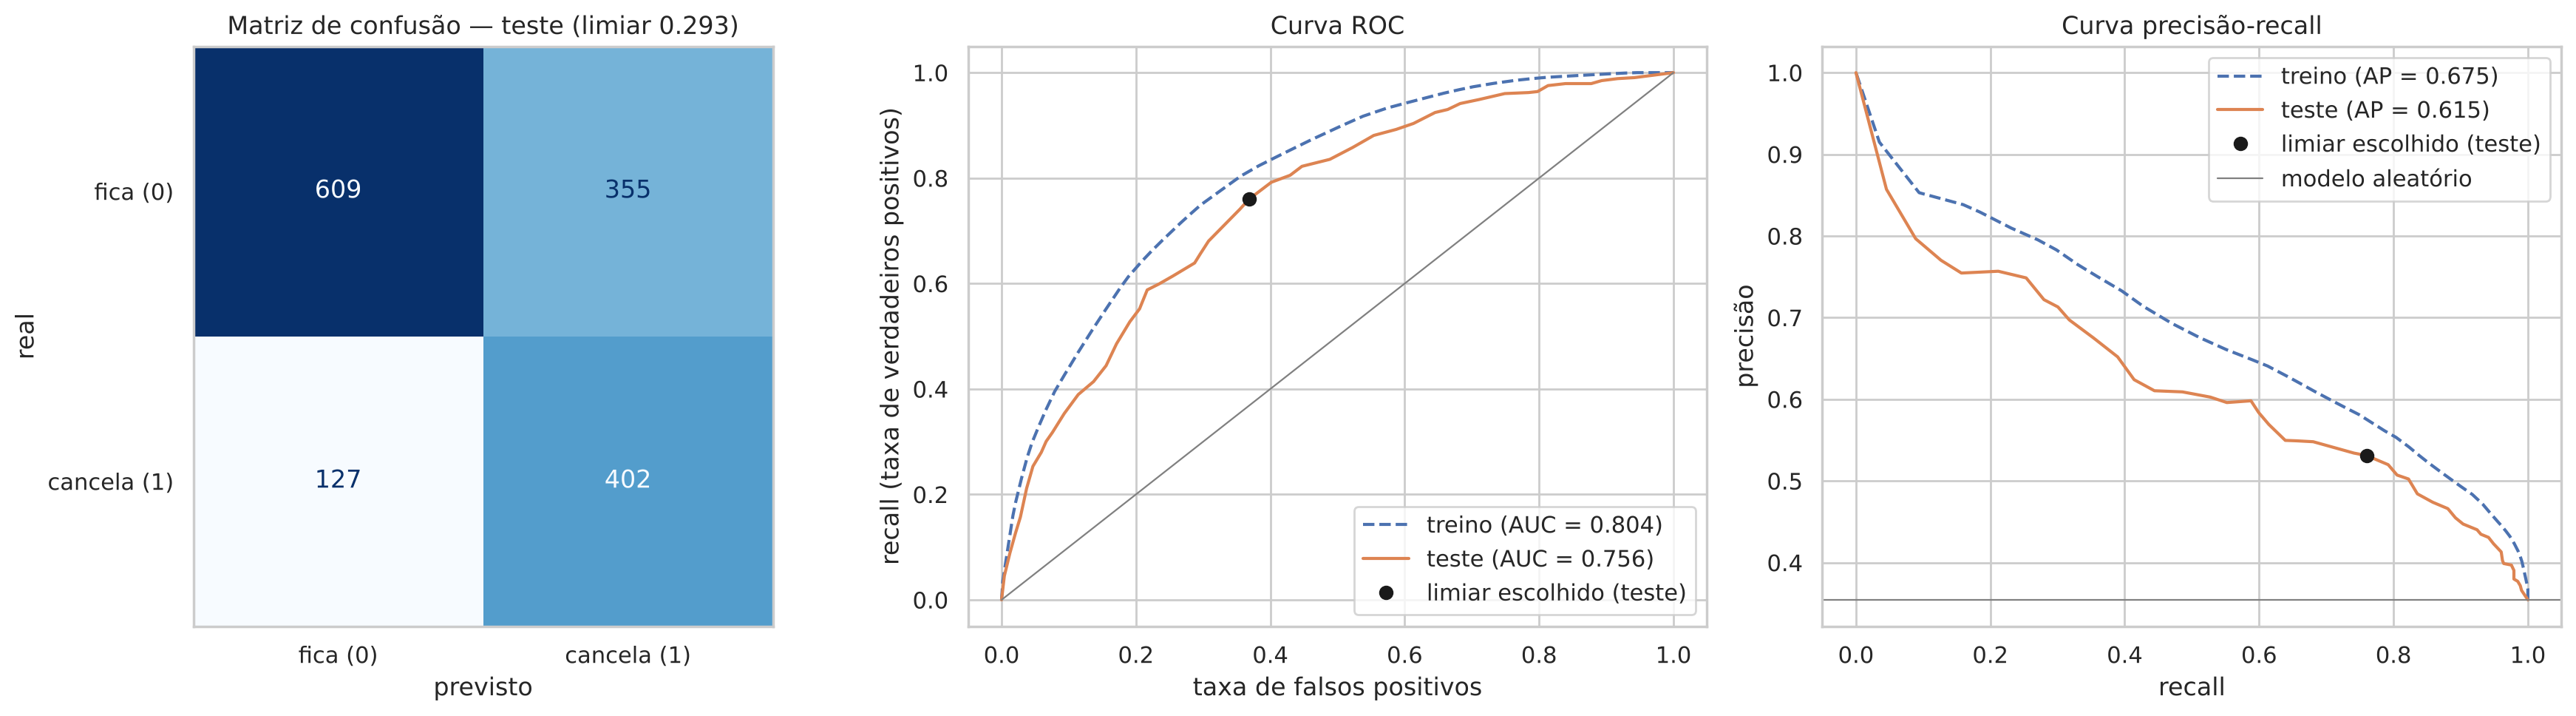

No teste: 402 de 529 cancelamentos antecipados (76.0%) e 127 não detectados.
Clientes acionados: 757 de 1493 (50.7%), dos quais 355 ficariam de qualquer forma.
A cada 1.88 clientes acionados, 1 é de fato um cliente que cancelaria (acionando ao acaso, seriam 2.82).


In [13]:
fig, eixos = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_teste, (prob_teste >= limiar_escolhido).astype(int),
                                        display_labels=["fica (0)", "cancela (1)"], cmap="Blues", ax=eixos[0], colorbar=False)
eixos[0].set(title=f"Matriz de confusão — teste (limiar {limiar_escolhido:.3f})", xlabel="previsto", ylabel="real")
eixos[0].grid(False)

for conjunto, y, prob, estilo in [("treino", y_treino, prob_treino, "--"), ("teste", y_teste, prob_teste, "-")]:
    fpr, tpr, _ = roc_curve(y, prob)
    eixos[1].plot(fpr, tpr, estilo, label=f"{conjunto} (AUC = {roc_auc_score(y, prob):.3f})")
    prec, rec, _ = precision_recall_curve(y, prob)
    eixos[2].plot(rec, prec, estilo, label=f"{conjunto} (AP = {average_precision_score(y, prob):.3f})")
fpr_ponto = ((prob_teste >= limiar_escolhido) & (y_teste == 0)).sum() / (y_teste == 0).sum()
eixos[1].plot(fpr_ponto, m_te["recall"], "ko", label="limiar escolhido (teste)")
eixos[1].plot([0, 1], [0, 1], c="grey", lw=0.8)
eixos[1].set(title="Curva ROC", xlabel="taxa de falsos positivos", ylabel="recall (taxa de verdadeiros positivos)")
eixos[2].plot(m_te["recall"], m_te["precisão"], "ko", label="limiar escolhido (teste)")
eixos[2].axhline(y_teste.mean(), c="grey", lw=0.8, label="modelo aleatório")
eixos[2].set(title="Curva precisão-recall", xlabel="recall", ylabel="precisão")
eixos[1].legend(); eixos[2].legend(); plt.tight_layout(); plt.show()

vp = int(((prob_teste >= limiar_escolhido) & (y_teste == 1)).sum()); fn = int(((prob_teste < limiar_escolhido) & (y_teste == 1)).sum())
fp = int(((prob_teste >= limiar_escolhido) & (y_teste == 0)).sum()); vn = int(((prob_teste < limiar_escolhido) & (y_teste == 0)).sum())
print(f"No teste: {vp} de {vp + fn} cancelamentos antecipados ({vp / (vp + fn):.1%}) e {fn} não detectados.")
print(f"Clientes acionados: {vp + fp} de {len(y_teste)} ({(vp + fp) / len(y_teste):.1%}), dos quais {fp} ficariam de qualquer forma.")
print(f"A cada {(vp + fp) / vp:.2f} clientes acionados, 1 é de fato um cliente que cancelaria "
      f"(acionando ao acaso, seriam {1 / y_teste.mean():.2f}).")

Em números absolutos, o modelo antecipa **402 dos 529 cancelamentos** do teste e deixa escapar 127. Para isso, aciona 757 clientes, dos quais 355 não cancelariam. Dito de outra forma, a cada 1,88 cliente acionado um é de fato um cliente em risco, contra 2,82 de uma escolha aleatória, o que representa uma redução de um terço no custo das campanhas para o mesmo número de clientes retidos.

As curvas completam a leitura. A curva ROC do teste fica bem acima da diagonal em toda a sua extensão, e o ponto escolhido (recall de 76% com 37% de falsos positivos) está na região em que a curva começa a se achatar, isto é, em que ganhar recall passa a custar muitos falsos positivos. A curva precisão-recall, por sua vez, mostra que o modelo é bastante preciso para os poucos clientes de maior risco (precisão acima de 75% até cerca de 20% de recall), mas que a precisão cai gradualmente à medida que se busca alcançar mais clientes. Em ambas, a curva tracejada do treino fica sistematicamente acima da do teste, o que é a expressão visual do gap medido na Seção 7.1.

### 7.3 Curvas de aprendizado

Por fim, as ***curvas de aprendizado*** respondem a uma pergunta diferente das anteriores: o que aconteceria se tivéssemos mais dados? Para isso, a árvore escolhida é treinada com frações crescentes do treino (de 10% a 100%), sempre validada nas mesmas dobras. Se as duas curvas convergirem para um patamar, o modelo atingiu o seu limite e mais dados não ajudariam muito; se ainda houver uma distância grande entre elas, o modelo está sobreajustado e mais dados (ou mais regularização) reduziriam o gap. Para comparação, a mesma curva é traçada para a árvore sem restrições.

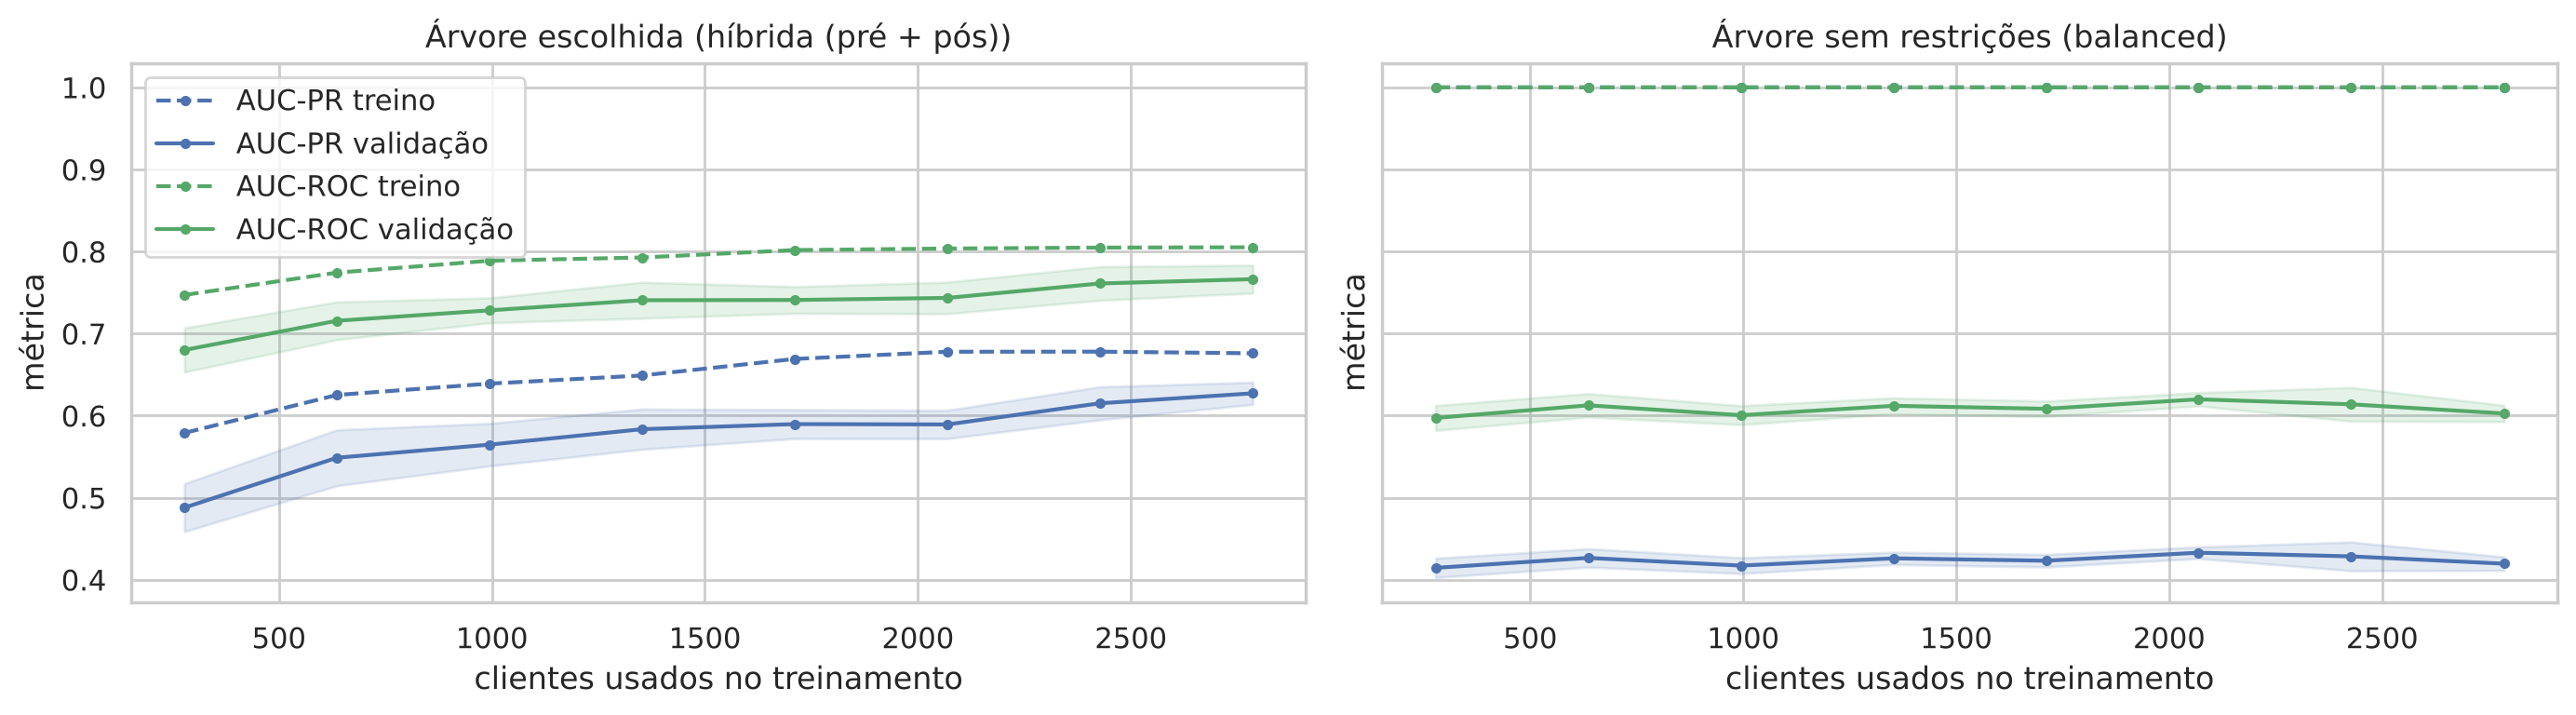

In [14]:
fracoes = np.linspace(0.1, 1.0, 8)
fig, eixos = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for eixo, (titulo, modelo) in zip(eixos, [(f"Árvore escolhida ({nome_escolhida})", pipeline_arvore(**params_escolhida)),
                                          ("Árvore sem restrições (balanced)", pipeline_arvore(class_weight="balanced"))]):
    for metrica, scorer, cor in [("AUC-PR", "average_precision", "C0"), ("AUC-ROC", "roc_auc", "C2")]:
        n, tr, va = learning_curve(modelo, X_treino, y_treino, cv=dobras, scoring=scorer, train_sizes=fracoes,
                                   n_jobs=-1, shuffle=True, random_state=config.RANDOM_STATE)
        eixo.plot(n, tr.mean(axis=1), "--o", c=cor, ms=3, label=f"{metrica} treino")
        eixo.plot(n, va.mean(axis=1), "-o", c=cor, ms=3, label=f"{metrica} validação")
        eixo.fill_between(n, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), color=cor, alpha=0.15)
    eixo.set(title=titulo, xlabel="clientes usados no treinamento", ylabel="métrica")
eixos[0].legend(); plt.tight_layout(); plt.show()

As duas curvas contrastam de forma marcante. Na árvore escolhida, a AUC-PR de validação cresce de cerca de 0,49, com 280 clientes, até 0,63, com o treino completo, enquanto a de treino se estabiliza perto de 0,68; desse modo, a distância entre as duas diminui à medida que os dados aumentam. Como a curva de validação ainda está subindo no fim, há indícios de que **mais dados ainda melhorariam** o modelo: ele é limitado pela quantidade de exemplos, e não pela sua capacidade.

Na árvore sem restrições, ao contrário, o treino fica cravado em 1,0 com qualquer quantidade de dados, ao passo que a validação permanece estacionada em torno de 0,42. Isso mostra que mais dados **não** resolveriam o problema dessa árvore: ela simplesmente decoraria uma amostra maior. O sobreajuste extremo só se resolve com controle de complexidade, e foi exatamente isso que as Seções 4 e 5 fizeram.

## 8. Interpretação: regras e atributos de risco

### 8.1 A árvore desenhada

A grande vantagem da árvore sobre o XGBoost é que ela pode ser lida. O desenho abaixo mostra os três primeiros níveis da árvore escolhida. Em cada nó aparecem a pergunta, a impureza (entropia), o número de clientes de treino e a quantidade de clientes de cada classe (`value = [fica, cancela]`); a cor indica a classe prevista (laranja para "fica" e azul para "cancela") e fica mais intensa quanto mais puro é o nó. Os limiares estão em unidades padronizadas, porque é assim que a árvore enxerga os dados; por esse motivo, a seção seguinte converte as regras de volta para a escala original.

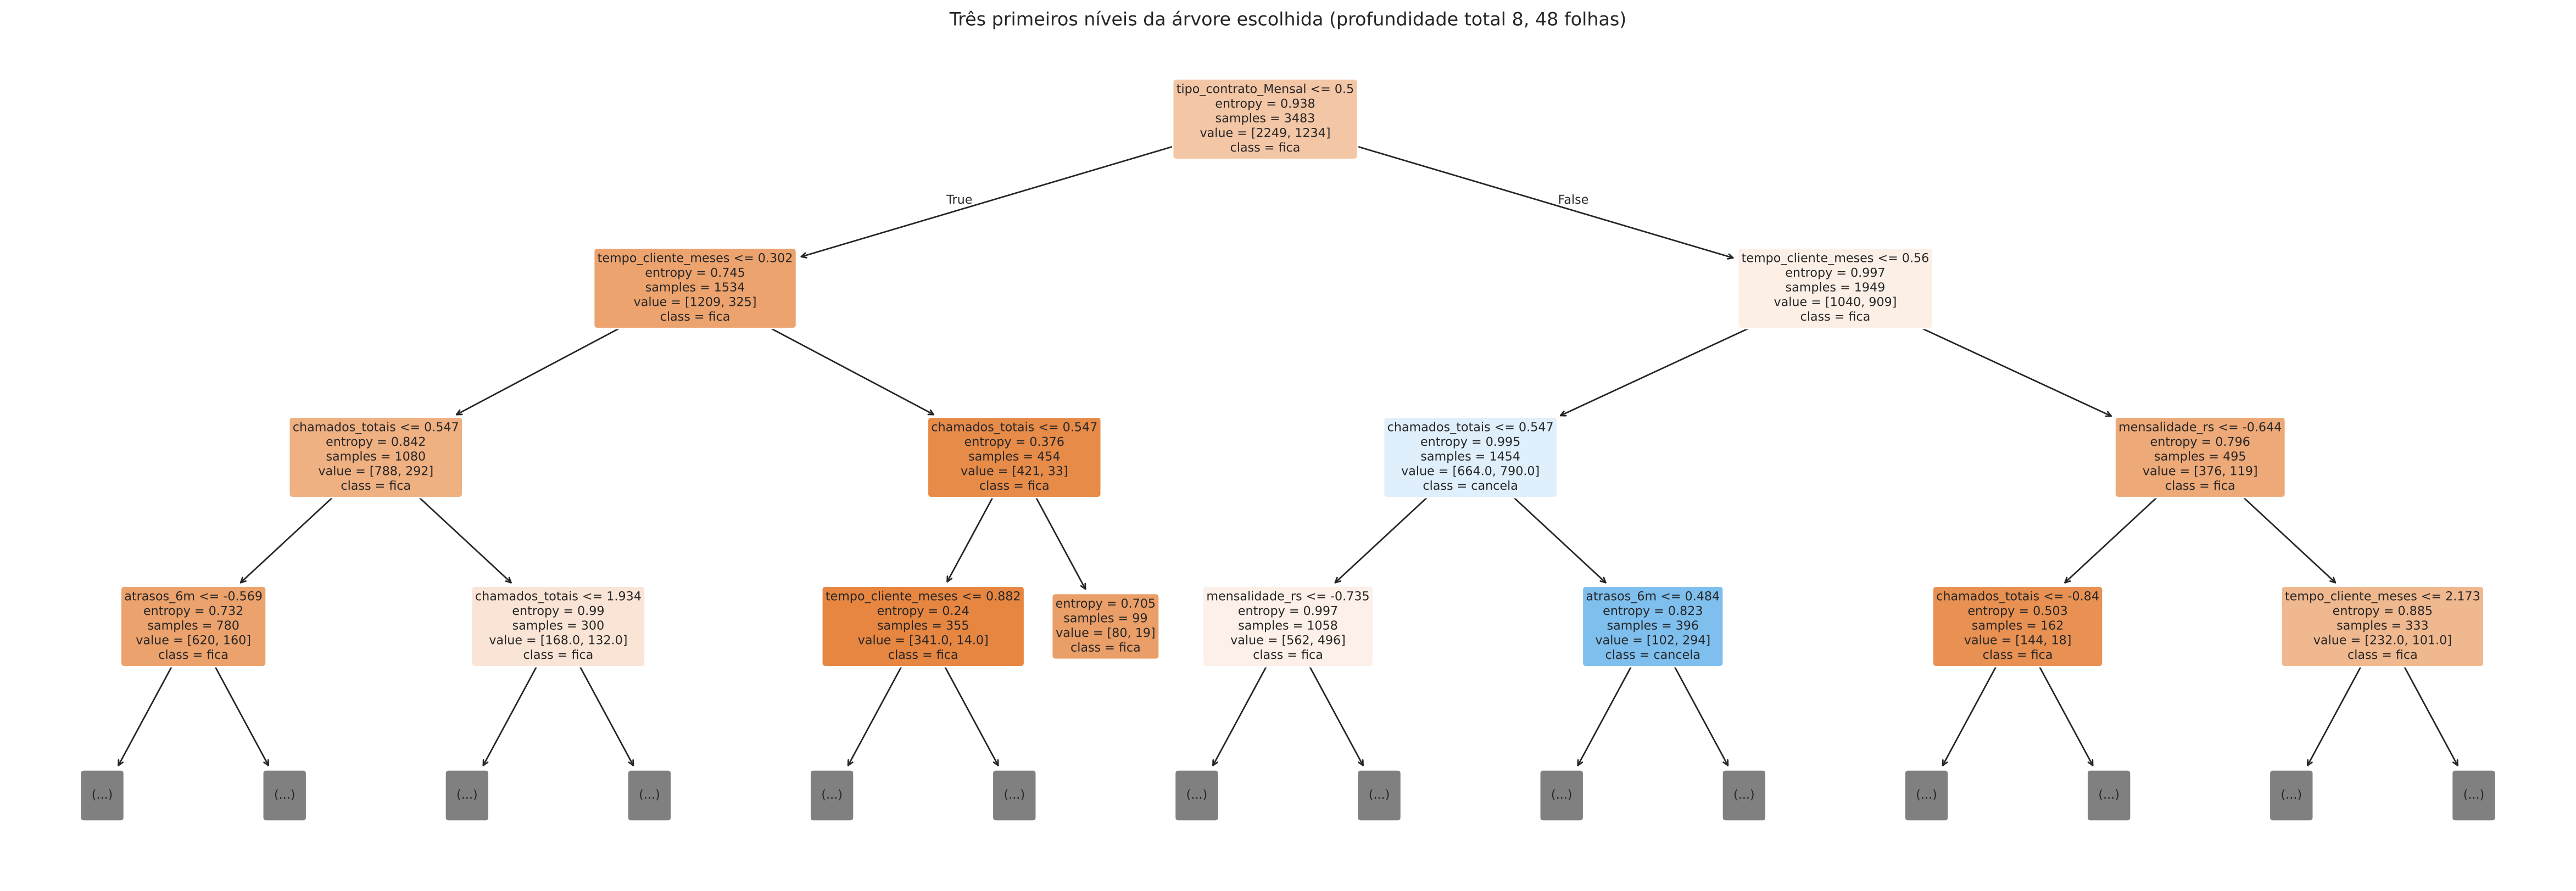

In [15]:
prep_final = arvore_final["prep"]
modelo_final = arvore_final["modelo"]
fig, eixo = plt.subplots(figsize=(30, 10))
plot_tree(modelo_final, max_depth=3, feature_names=prep_final.colunas_saida_, class_names=["fica", "cancela"],
          filled=True, rounded=True, impurity=True, proportion=False, fontsize=8, ax=eixo)
eixo.set_title(f"Três primeiros níveis da árvore escolhida (profundidade total {modelo_final.get_depth()}, "
               f"{modelo_final.get_n_leaves()} folhas)")
plt.show()

### 8.2 Regras SE-ENTÃO na unidade original

Cada caminho da raiz até um nó é uma regra do tipo ***SE condição 1 E condição 2 E ... ENTÃO classe***. A função abaixo percorre a árvore até a profundidade 3 e, para cada regra, faz três coisas. Primeiro, converte os limiares das numéricas de volta para meses, reais, chamados e atrasos, usando a média e o desvio padrão do próprio escalador ($x = z\,\sigma + \mu$); para as variáveis inteiras, o corte é arredondado para o inteiro correspondente (por exemplo, "≤ 2,4 chamados" vira "≤ 2 chamados"). Segundo, reescreve as colunas one-hot e binárias em linguagem natural (`tipo_contrato_Mensal ≤ 0,5` vira "contrato ≠ Mensal"), juntando condições redundantes sobre a mesma variável. Terceiro, mede, com os clientes reais do treino, quantos clientes a regra cobre e qual é a taxa de churn **real** entre eles, sem a ponderação do `class_weight`. Por fim, a coluna ENTÃO usa o **limiar escolhido na Seção 6** (0,293), e não a maioria da folha: uma regra diz "cancela" quando os clientes que caem nela seriam acionados pelo modelo no ponto de operação de 80% de recall. Assim, as regras descrevem exatamente a decisão que o modelo toma, e não a de um limiar de 0,5 que não usamos.

In [16]:
INTEIRAS = {"tempo_cliente_meses", "chamados_totais", "atrasos_6m"}
UNIDADE = {"tempo_cliente_meses": " meses", "chamados_totais": " chamados", "atrasos_6m": " atrasos"}

def texto_intervalo(coluna, baixo, alto):
    if coluna in INTEIRAS:                      # x > 2,4 -> x >= 3 ; x <= 2,4 -> x <= 2
        b = None if np.isinf(baixo) else int(np.floor(baixo + 1e-9)) + 1
        a = None if np.isinf(alto) else int(np.floor(alto + 1e-9))
        u = UNIDADE[coluna]
        if b is not None and a is not None:
            return f"{coluna} entre {b} e {a}{u}" if a > b else f"{coluna} = {a}{u}"
        if b is None and a == 0:
            return f"{coluna} = 0{u}"
        return f"{coluna} ≥ {b}{u}" if b is not None else f"{coluna} ≤ {a}{u}"
    fmt = lambda v: f"R$ {v:.2f}".replace(".", ",")
    if not np.isinf(baixo) and not np.isinf(alto):
        return f"{fmt(baixo)} < {coluna} ≤ {fmt(alto)}"
    return f"{coluna} > {fmt(baixo)}" if not np.isinf(baixo) else f"{coluna} ≤ {fmt(alto)}"

def texto_regra(condicoes, prep):
    limites, categorias, binarias = {}, {}, {}
    todas = dict(zip(config.CATEGORICAS, [list(c) for c in prep.codificador_.categories_]))
    for coluna, limiar, lado in condicoes:
        if coluna in config.NUMERICAS:
            v = prep.para_escala_original(coluna, limiar)
            b, a = limites.get(coluna, (-np.inf, np.inf))
            limites[coluna] = (b, min(a, v)) if lado == "<=" else (max(b, v), a)
        elif variavel_de_origem(coluna) in config.CATEGORICAS:
            origem = variavel_de_origem(coluna); categoria = coluna[len(origem) + 1:]
            permitidas = categorias.get(origem, set(todas[origem]))
            categorias[origem] = permitidas - {categoria} if lado == "<=" else permitidas & {categoria}
        else:
            binarias[coluna] = 0 if lado == "<=" else 1
    partes = [texto_intervalo(c, *lim) for c, lim in limites.items()]
    for origem, permitidas in categorias.items():
        ordem = [c for c in todas[origem] if c in permitidas]
        partes.append(f"{origem} = {ordem[0]}" if len(ordem) == 1 else f"{origem} ∈ {{{', '.join(ordem)}}}")
    partes += [f"{c} = {v}" for c, v in binarias.items()]
    return " E ".join(partes) if partes else "(todos os clientes)"

def extrair_regras(modelo, prep, Z, y, profundidade_max=3):
    arvore, nomes = modelo.tree_, prep.colunas_saida_
    caminhos = modelo.decision_path(Z)          # matriz cliente × nó: 1 se o cliente passa pelo nó
    n_no = np.asarray(caminhos.sum(axis=0)).ravel()
    churn_no = np.asarray(caminhos.T @ y.to_numpy()).ravel()
    regras = []
    def visitar(no, profundidade, condicoes):
        folha = arvore.children_left[no] == -1
        if folha or profundidade == profundidade_max:
            regras.append({"SE": texto_regra(condicoes, prep),
                           # Rótulo pelo limiar escolhido na Seção 6 (e não pela maioria, que equivaleria a 0,5).
                           "ENTÃO": "cancela" if arvore.value[no][0][1] / arvore.value[no][0].sum() >= limiar_escolhido else "fica",
                           "clientes": int(n_no[no]), "% do treino": n_no[no] / len(y),
                           "churn real": churn_no[no] / n_no[no], "nó final?": "folha" if folha else "segue"})
            return
        coluna, limiar = nomes[arvore.feature[no]], arvore.threshold[no]
        visitar(arvore.children_left[no], profundidade + 1, condicoes + [(coluna, limiar, "<=")])
        visitar(arvore.children_right[no], profundidade + 1, condicoes + [(coluna, limiar, ">")])
    visitar(0, 0, [])
    return pd.DataFrame(regras).sort_values("churn real", ascending=False).reset_index(drop=True)

Z_final = prep_final.transform(X_treino)
regras = extrair_regras(modelo_final, prep_final, Z_final, y_treino, profundidade_max=3)
print(f"Taxa de churn no treino: {y_treino.mean():.1%}")
def formatar(tabela):
    tabela = tabela.copy()
    for coluna in ["% do treino", "churn real"]:
        tabela[coluna] = tabela[coluna].map("{:.1%}".format)
    return tabela

print("Regras do topo da árvore (até a profundidade 3):")
display(formatar(regras))

# Complemento: as folhas completas de maior e de menor risco (regras inteiras, até o fim do caminho).
folhas = extrair_regras(modelo_final, prep_final, Z_final, y_treino, profundidade_max=99)
print(f"\nAs 5 folhas de maior risco e as 3 de menor risco (de {len(folhas)} folhas):")
display(formatar(pd.concat([folhas.head(5), folhas.tail(3)])))

Taxa de churn no treino: 35.4%
Regras do topo da árvore (até a profundidade 3):


,SE,ENTÃO,clientes,% do treino,churn real,nó final?
0,tempo_cliente_meses ≤ 33 meses E chamados_totais ≥ 3 chamados E tipo_contrato = Mensal,cancela,396,11.4%,74.2%,segue
1,tempo_cliente_meses ≤ 33 meses E chamados_totais ≤ 2 chamados E tipo_contrato = Mensal,cancela,1058,30.4%,46.9%,segue
2,"tempo_cliente_meses ≤ 29 meses E chamados_totais ≥ 3 chamados E tipo_contrato ∈ {Anual, Bienal}",cancela,300,8.6%,44.0%,segue
3,"tempo_cliente_meses ≥ 34 meses E mensalidade_rs > R$ 71,71 E tipo_contrato = Mensal",cancela,333,9.6%,30.3%,segue
4,"tempo_cliente_meses ≤ 29 meses E chamados_totais ≤ 2 chamados E tipo_contrato ∈ {Anual, Bienal}",fica,780,22.4%,20.5%,segue
5,"tempo_cliente_meses ≥ 30 meses E chamados_totais ≥ 3 chamados E tipo_contrato ∈ {Anual, Bienal}",fica,99,2.8%,19.2%,folha
6,"tempo_cliente_meses ≥ 34 meses E mensalidade_rs ≤ R$ 71,71 E tipo_contrato = Mensal",fica,162,4.7%,11.1%,segue
7,"tempo_cliente_meses ≥ 30 meses E chamados_totais ≤ 2 chamados E tipo_contrato ∈ {Anual, Bienal}",fica,355,10.2%,3.9%,segue



As 5 folhas de maior risco e as 3 de menor risco (de 48 folhas):


,SE,ENTÃO,clientes,% do treino,churn real,nó final?
0,tempo_cliente_meses ≤ 10 meses E chamados_totais ≥ 3 chamados E atrasos_6m ≥ 2 atrasos E tipo_contrato = Mensal,cancela,47,1.3%,91.5%,folha
1,tempo_cliente_meses entre 11 e 33 meses E chamados_totais ≥ 3 chamados E atrasos_6m ≥ 2 atrasos E tipo_contrato = Mensal,cancela,89,2.6%,82.0%,folha
2,"tempo_cliente_meses ≤ 14 meses E chamados_totais ≥ 3 chamados E atrasos_6m ≤ 1 atrasos E mensalidade_rs > R$ 87,18 E tipo_contrato = Mensal",cancela,99,2.8%,81.8%,folha
3,"tempo_cliente_meses ≤ 23 meses E chamados_totais ≤ 2 chamados E R$ 96,81 < mensalidade_rs ≤ R$ 100,04 E atrasos_6m ≤ 1 atrasos E tipo_contrato = Mensal",cancela,40,1.1%,77.5%,folha
4,"tempo_cliente_meses ≤ 13 meses E chamados_totais ≤ 2 chamados E mensalidade_rs > R$ 70,05 E atrasos_6m ≥ 2 atrasos E tipo_contrato = Mensal",cancela,77,2.2%,74.0%,folha
45,"tempo_cliente_meses entre 20 e 29 meses E chamados_totais ≤ 2 chamados E atrasos_6m = 0 atrasos E mensalidade_rs ≤ R$ 70,43 E tipo_contrato ∈ {Anual, Bienal}",fica,42,1.2%,2.4%,folha
46,"tempo_cliente_meses ≥ 39 meses E chamados_totais ≤ 2 chamados E mensalidade_rs ≤ R$ 64,18 E tipo_contrato ∈ {Anual, Bienal}",fica,42,1.2%,0.0%,folha
47,"tempo_cliente_meses ≥ 39 meses E chamados_totais ≤ 2 chamados E mensalidade_rs > R$ 90,46 E tipo_contrato ∈ {Anual, Bienal}",fica,80,2.3%,0.0%,folha


A raiz da árvore separa os clientes pelo **tipo de contrato**, e os dois níveis seguintes usam o **tempo de casa** e o **número de chamados**. As regras do topo podem ser lidas como um retrato do risco:

- **SE** o contrato é mensal **E** o cliente tem até 33 meses de casa **E** abriu 3 ou mais chamados, **ENTÃO** o risco é alto: 396 clientes (11,4% do treino), dos quais **74,2% cancelaram**, mais que o dobro da taxa geral de 35,4%.
- **SE** o contrato é mensal **E** o cliente tem até 33 meses **E** abriu até 2 chamados, o risco ainda é elevado (46,9%) e, no limiar de 0,293, esse grupo já é acionado, mesmo sem ter maioria de cancelamentos; ainda assim, a árvore continua dividindo esse grupo, que é o maior da base (1.058 clientes), usando a mensalidade e os atrasos.
- Mesmo entre os contratos anuais e bienais, o atrito pesa: com até 29 meses e 3 ou mais chamados, **44,0%** cancelam, acima da média e, portanto, acima do limiar de acionamento.
- No extremo oposto, **SE** o contrato não é mensal **E** o cliente tem 30 meses ou mais **E** abriu até 2 chamados, **ENTÃO** quase ninguém sai (**3,9%**).

As folhas completas tornam o perfil ainda mais nítido. As três de maior risco combinam contrato mensal, poucos meses de casa e sinais de atrito: com até 10 meses, 3 ou mais chamados e 2 ou mais atrasos, **91,5%** dos clientes cancelaram; entre 11 e 33 meses com o mesmo atrito, 82,0%; e, sem atrasos mas com mensalidade acima de R\$ 87,18, 81,8%. As folhas de menor risco, ao contrário, reúnem contratos longos, clientes antigos e poucos chamados, com churn próximo de zero.

Em resumo, as regras descrevem um ***tripé de risco*** — **contrato sem fidelidade, cliente recente e sinais de atrito (chamados e atrasos)** — que coincide com os achados da análise exploratória do Relatório 02. Essa coerência é, por si só, um indício de que a árvore aprendeu padrões reais, e não ruído. Além disso, as regras são diretamente acionáveis: sugerem, por exemplo, priorizar clientes mensais com menos de três anos de casa logo após o terceiro chamado, ou oferecer migração para contratos anuais aos clientes mensais com atrasos.

### 8.3 Importância dos atributos

O miniprojeto pede o ranking de importância dos atributos. Usamos, no entanto, dois métodos, porque cada um responde a uma pergunta diferente e ambos têm limitações conhecidas:

- A **importância por redução de impureza** (MDI, `feature_importances_`) soma quanto cada variável reduziu a impureza em todas as divisões em que foi usada, ponderado pelo número de clientes. É gratuita, pois vem do próprio treinamento; por outro lado, é calculada no treino e tende a favorecer variáveis com muitos valores distintos, como a mensalidade. Para comparar com o outro método, somamos as importâncias das colunas one-hot de cada variável original.
- A **importância por permutação** embaralha uma variável de cada vez **no teste** e mede quanto a AUC-PR cai. Se o desempenho despenca, o modelo dependia daquela variável para generalizar. Como o embaralhamento é feito nas colunas brutas, antes do `Pipeline`, ela já mede cada variável original como um todo (o contrato inteiro, e não cada coluna one-hot). Repetimos o embaralhamento 30 vezes para obter a média e a dispersão.

,permutação: queda de AUC-PR (teste),desvio,MDI (treino)
tipo_contrato,0.089,0.011,0.258
tempo_cliente_meses,0.063,0.012,0.297
chamados_totais,0.059,0.010,0.213
atrasos_6m,0.037,0.009,0.098
mensalidade_rs,0.028,0.008,0.109
fibra_optica,0.005,0.003,0.015
debito_automatico,0.000,0.000,0.000
mensalidade_ausente,0.000,0.000,0.000
forma_pagamento,-0.001,0.002,0.011


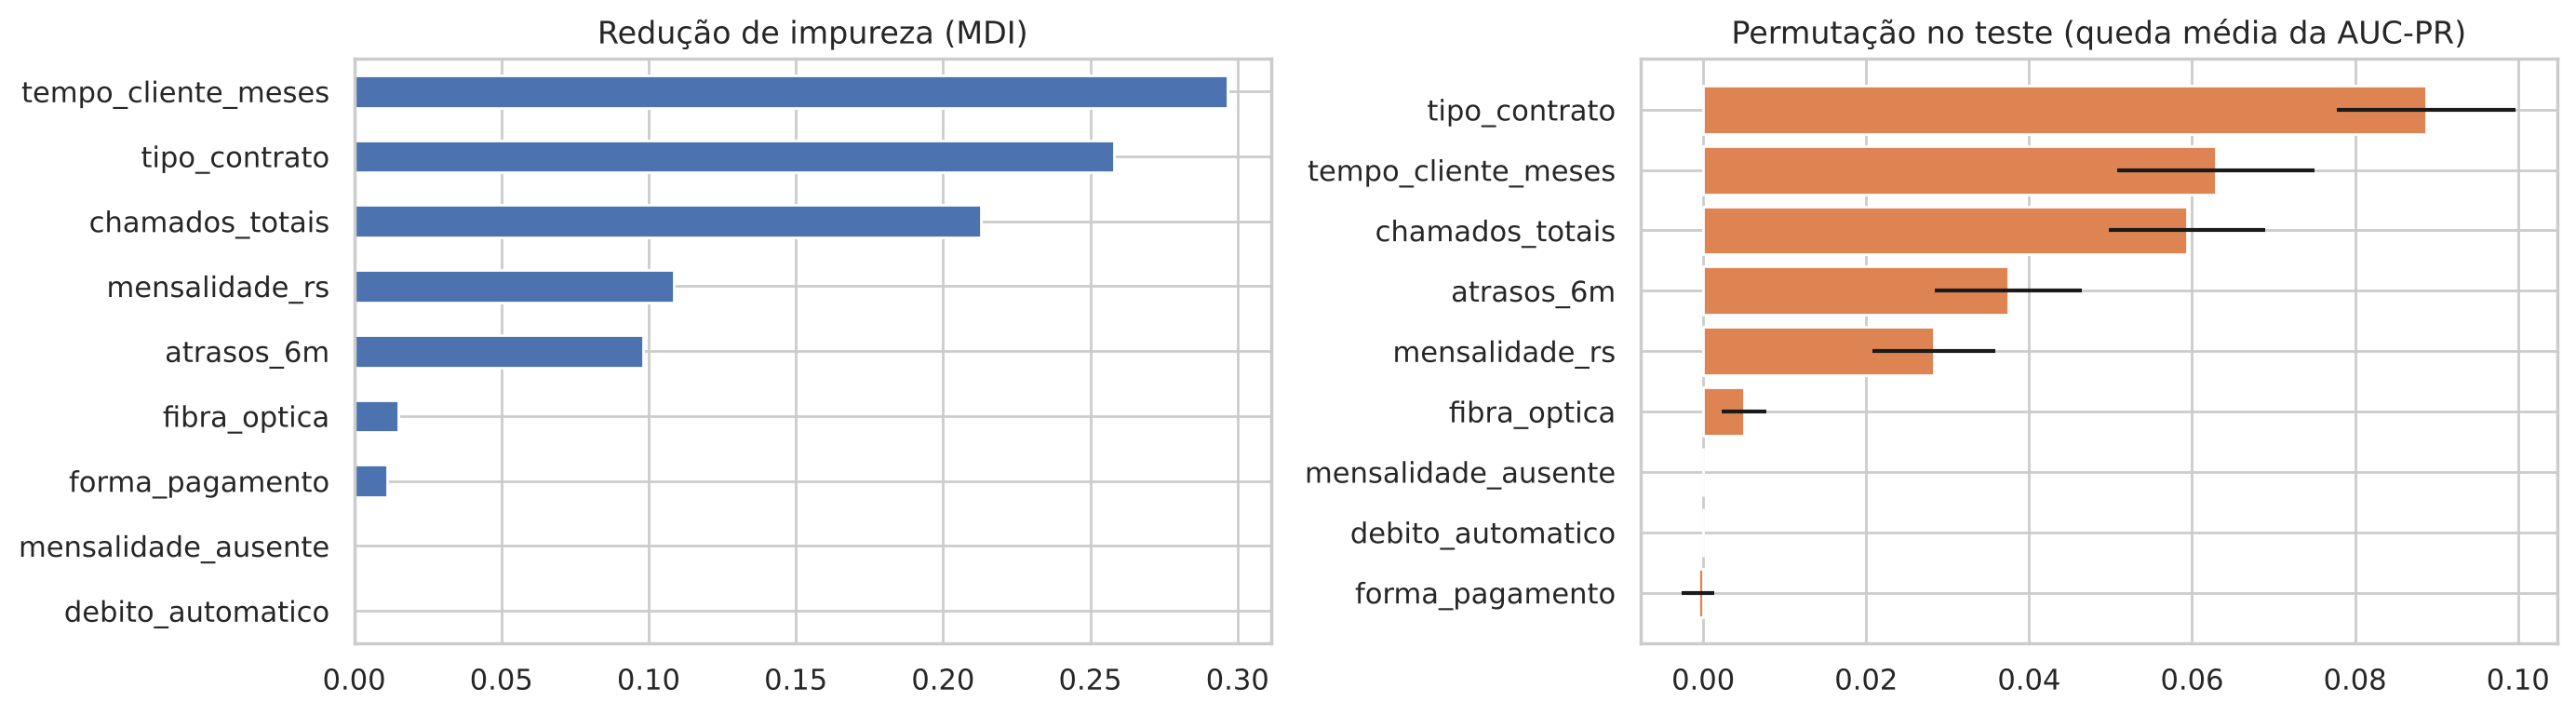

In [17]:
mdi = (pd.Series(modelo_final.feature_importances_, index=prep_final.colunas_saida_)
         .groupby(variavel_de_origem).sum().rename("MDI (treino)"))
# mensalidade_ausente é derivada de mensalidade_rs: na permutação, as duas são embaralhadas juntas.
permutacao = permutation_importance(arvore_final, X_teste, y_teste, scoring="average_precision", n_repeats=30,
                                    random_state=config.RANDOM_STATE, n_jobs=-1)
perm = pd.DataFrame({"permutação: queda de AUC-PR (teste)": permutacao.importances_mean,
                     "desvio": permutacao.importances_std}, index=COLUNAS_ENTRADA)
importancias = perm.join(mdi, how="outer").fillna(0).sort_values("permutação: queda de AUC-PR (teste)", ascending=False)
display(importancias.round(3))

fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
importancias["MDI (treino)"].sort_values().plot.barh(ax=eixos[0], color="C0", title="Redução de impureza (MDI)")
ordem = importancias["permutação: queda de AUC-PR (teste)"].sort_values()
eixos[1].barh(ordem.index, ordem, xerr=importancias.loc[ordem.index, "desvio"], color="C1")
eixos[1].set(title="Permutação no teste (queda média da AUC-PR)")
plt.tight_layout(); plt.show()

Os dois métodos concordam no essencial: **tipo de contrato, tempo de casa e chamados** formam o trio dominante, seguidos, a uma distância considerável, por atrasos e mensalidade. Na permutação, embaralhar o tipo de contrato derruba a AUC-PR de teste em 0,089, o maior efeito; embaralhar o tempo de casa ou os chamados custa cerca de 0,06 cada.

As diferenças entre os métodos, por outro lado, ilustram as limitações conhecidas da MDI. Ela coloca o tempo de casa à frente do contrato e dá à mensalidade mais importância que aos atrasos (0,109 contra 0,098), ao passo que a permutação inverte as duas ordens. Isso é coerente com o viés da MDI a favor de variáveis contínuas, que oferecem muitos pontos de corte e, por isso, são escolhidas com mais frequência nas divisões profundas, inclusive para ajustar ruído.

Por fim, três variáveis praticamente não contribuem: `forma_pagamento`, o que confirma o diagnóstico do Relatório 02 de que ela não diferencia os clientes; `mensalidade_ausente`, o que indica que o possível sinal da ausência, levantado no MP1, não se sustentou no modelo; e `debito_automatico`, o que é mais surpreendente, já que a análise exploratória havia mostrado uma diferença de churn de 12 pontos percentuais (40,1% contra 28,2%). Uma explicação plausível é que a informação do débito automático já está contida em outras variáveis usadas pela árvore, assim como a fibra óptica, que tem baixa importância porque a mensalidade (correlação de 0,85) carrega quase a mesma informação. Esse ponto será retomado no Relatório 05: se o XGBoost, que combina centenas de árvores, também ignorar essas variáveis, elas serão fortes candidatas a remoção.

## 9. Exportação dos resultados

Para que o Relatório 05 compare o XGBoost com a árvore em condições idênticas, salvamos em `resultados/arvore_escolhida.json` os hiperparâmetros da árvore escolhida, o seu limiar e as métricas de validação cruzada e de teste. O Relatório 05 recria a árvore a partir desses hiperparâmetros (o treinamento é determinístico, graças ao `random_state`), em vez de depender de um arquivo binário do modelo.

In [18]:
def para_json(v):
    # Converte tipos do numpy para tipos nativos do Python (o json não sabe serializar np.float64).
    return v.item() if hasattr(v, "item") else v

resultado = {
    "modelo": "DecisionTreeClassifier",
    "estrategia": nome_escolhida,
    # Só os hiperparâmetros diferentes do padrão: o arquivo fica legível e compatível com outras versões do scikit-learn.
    "hiperparametros": {k: para_json(v) for k, v in params_escolhida.items() if v != DecisionTreeClassifier().get_params()[k]},
    "random_state": config.RANDOM_STATE,
    "limiar": limiar_escolhido,
    "profundidade": int(modelo_final.get_depth()),
    "folhas": int(modelo_final.get_n_leaves()),
    "validacao_cruzada": {k: para_json(v) for k, v in comparacao.loc[nome_escolhida].items()
                          if "(validação)" in k},
    "recall_alvo": config.RECALL_ALVO,
    "teste": {k: para_json(v) for k, v in m_te.items()},
}
config.RESULTADOS.mkdir(parents=True, exist_ok=True)
with open(config.ARVORE_ESCOLHIDA, "w", encoding="utf-8") as arquivo:
    json.dump(resultado, arquivo, ensure_ascii=False, indent=2)
print(f"Salvo em {config.ARVORE_ESCOLHIDA.relative_to(config.RAIZ)}")
print(json.dumps(resultado, ensure_ascii=False, indent=2))

Salvo em resultados/arvore_escolhida.json
{
  "modelo": "DecisionTreeClassifier",
  "estrategia": "híbrida (pré + pós)",
  "hiperparametros": {
    "ccp_alpha": 0.0003606324172236214,
    "criterion": "entropy",
    "max_depth": 8,
    "min_samples_leaf": 40,
    "min_samples_split": 100
  },
  "random_state": 42,
  "limiar": 0.2926829268292683,
  "profundidade": 8,
  "folhas": 48,
  "validacao_cruzada": {
    "AUC_PR (validação)": 0.6272068682367248,
    "AUC_ROC (validação)": 0.7663231340349255,
    "recall (validação)": 0.5041111220828807,
    "precisao (validação)": 0.630728849133643,
    "F2 (validação)": 0.5227432252889257,
    "acuracia (validação)": 0.7180605715793467,
    "AUC_PR desvio (validação)": 0.013509078996799468
  },
  "recall_alvo": 0.8,
  "teste": {
    "recall": 0.7599243856332704,
    "precisão": 0.5310435931307794,
    "F2": 0.6996171249564914,
    "acurácia": 0.6771600803750837,
    "% acionados": 0.507032819825854,
    "AUC-ROC": 0.75646428319306,
    "AUC-PR":

## 10. Conclusão

Este relatório mostrou, passo a passo, como transformar uma árvore de decisão que decora o treino em um modelo que generaliza. A árvore sem restrições acertava 100% do treino, mas tinha AUC-PR de apenas 0,426 na validação e acurácia inferior à de um classificador trivial. Depois do controle de complexidade, a árvore escolhida alcançou AUC-PR de **0,627** na validação cruzada e de **0,615** no teste, com um afastamento entre treino e teste cerca de dez vezes menor.

As principais conclusões são cinco:

1. **O critério de escolha importa tanto quanto o algoritmo.** Com 35,4% de churn, o F2 favorece a solução trivial de acionar todos os clientes (F2 = 0,733). Por isso, separamos a escolha do modelo (pela AUC-PR, que mede o ordenamento por risco) da escolha do ponto de operação (pelo recall-alvo de 80%).
2. **Pré-poda × pós-poda:** nesta base, a pré-poda por tamanho mínimo de folha (40 clientes) superou a pós-poda por custo-complexidade (AUC-PR de 0,627 contra 0,592), porque ataca diretamente a causa do sobreajuste: folhas com poucos clientes. A combinação das duas (árvore híbrida) manteve o desempenho com 3 folhas a menos e foi a escolhida.
3. **O balanceamento de classes é redundante quando o limiar é ajustado.** O `class_weight="balanced"` não alterou a AUC-PR; apenas deslocou o ponto de operação, o que a escolha do limiar já faz de forma explícita.
4. **No ponto de operação escolhido**, o modelo antecipa 76% dos cancelamentos do teste acionando metade da base, o que significa 1,88 cliente acionado por cancelamento detectado, contra 2,82 de uma escolha aleatória.
5. **O risco tem um perfil claro e interpretável:** contrato mensal, cliente recente e sinais de atrito (chamados e atrasos). Esse tripé aparece nas regras SE-ENTÃO, nos dois rankings de importância e na análise exploratória do MP1.

Ao mesmo tempo, os resultados apontam os limites da árvore. As suas probabilidades variam em degraus (uma por folha), o que dificulta ajustar o recall com precisão, e a curva de aprendizado indica que o modelo ainda ganharia com mais dados. Esses dois pontos motivam o Relatório 05: o ***XGBoost*** combina centenas de árvores, produz probabilidades contínuas e, em geral, extrai mais informação da mesma amostra. A pergunta que fica, então, é se esse ganho compensa a perda de interpretabilidade, e ela será respondida com o mesmo protocolo, as mesmas dobras e o mesmo recall-alvo usados aqui.

### Síntese da árvore escolhida

| Item | Valor |
| --- | --- |
| Estratégia | híbrida: pré-poda (GridSearch) + pós-poda (`ccp_alpha`) |
| Hiperparâmetros | `criterion="entropy"`, `max_depth=8`, `min_samples_leaf=40`, `min_samples_split=100`, `ccp_alpha≈0,00036`, `class_weight=None` |
| Tamanho | profundidade 8, 48 folhas |
| Validação cruzada (5 dobras) | AUC-PR 0,627 ± 0,014 · AUC-ROC 0,766 |
| Limiar (recall-alvo de 80% fora da dobra) | 0,293 |
| Teste | recall 0,760 · precisão 0,531 · AUC-PR 0,615 · AUC-ROC 0,756 · 50,7% da base acionada |
| Atributos dominantes | tipo de contrato, tempo de casa, chamados |

---
### Anexo — baixar o arquivo gerado (Colab)

Depois, suba-o em `resultados/` pelo GitHub (*Add file → Upload files*), para que o Relatório 05 o encontre.

In [19]:
# Só executa no Colab: baixa o resultado da árvore para o computador.
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(str(config.ARVORE_ESCOLHIDA))